## 0. Configuración

In [ ]:
import os
# --- Qué se ejecuta -------------------------------------------------------------------------------
EJECUTAR = {'M1': True, 'M2': True, 'M3': True, 'M4': False}
REPS = [int(r) for r in os.environ.get('REPS_S11B', '').split(',') if r] or list(range(1, 11))
REANUDAR = True            # reutiliza lo ya guardado en Drive (por REP y por parte)

# --- Rutas ----------------------------------------------------------------------------------------
CARPETA = os.environ.get('CARPETA_ARTICULO', '/content/drive/MyDrive/Articulo_Grupal_EdgeIIoT')
RUTA_CSV = os.environ.get('EDGE_CSV', os.path.join(CARPETA, 'DNN-EdgeIIoT-dataset.csv'))
DIR_V1 = os.path.join(CARPETA, 'corridas')                 # resultados v1 (solo lectura)
DIR_MEJ = os.path.join(CARPETA, 'mejoras')                 # todo lo nuevo
DIR_TMP = os.environ.get('DIR_TMP_S11B', '/content/tmp_s11b')   # disco local: datos de medición y modelos de paso
NB_CONSOLIDACION = os.environ.get('NB_CONSOLIDACION', '/content/drive/MyDrive/Colab Notebooks/S11_Consolidacion_Estadistica.ipynb')

# --- Parámetros de v1 (sección 13; no modificar) ---------------------------------------------------
TEST_SIZE = 0.30
SMOTE_K = 5
MI_SUBMUESTRA = 200_000
MI_MAX_DISCRETO = 64
MI_BINS = 32
LOTE_MEDICION = 1024
V1_VERSIONES = {'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1'}   # las de las fichas v1
COLS_RETIRAR = ['frame.time', 'ip.dst_host', 'http.file_data', 'ip.src_host', 'arp.src.proto_ipv4',
                'arp.dst.proto_ipv4', 'http.request.full_uri', 'http.request.uri.query',
                'icmp.transmit_timestamp', 'tcp.payload', 'tcp.options', 'tcp.srcport',
                'tcp.dstport', 'udp.port', 'mqtt.msg']
COLS_CATEGORICAS = ['http.request.method', 'http.referer', 'http.request.version',
                    'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']
GAO_18 = ['icmp.checksum', 'icmp.seq_le', 'http.response', 'tcp.ack', 'tcp.ack_raw',
          'tcp.connection.rst', 'tcp.connection.syn', 'udp.stream', 'dns.qry.name',
          'http.request.method-0', 'http.request.method-GET', 'http.request.method-POST',
          'http.referer-0', 'http.request.version-0', 'dns.qry.name.len-0.0',
          'mqtt.conack.flags-0.0', 'mqtt.protoname-0.0', 'mqtt.topic-0.0']
NOMBRE = {'tcn': 'TCN', 'rf': 'MI-LiteRF', 'xgb': 'MI-LiteXGB'}
ALFA = 0.05

# --- M1: benchmark de despliegue ---------------------------------------------------------------------
M1_N_LOTE1 = 10_000          # flujos para la latencia con lote de 1 en ONNX Runtime (mediana por flujo)
M1_N_LOTE1_NATIVO = 2_000    # en el runtime de v1 (Keras / scikit-learn / XGBoost), solo como referencia
M1_CALENTAMIENTO_LOTE1 = 500 # llamadas de calentamiento descartadas antes de medir con lote de 1
M1_OPSET = 17                # opset ONNX para la TCN y el RF (onnxmltools admite hasta 15 para XGBoost)

# --- M2: ablación (regla de lectura fijada antes) ------------------------------------------------------
MARGEN_RELEVANTE = 1.0       # puntos de F1 macro: diferencia mínima con relevancia práctica
#   Por brazo: Δ = F1(MI-LiteRF) − F1(brazo), prueba pareada bilateral (Shapiro → t o Wilcoxon), Holm sobre los 3 brazos.
#   «A favor de MI-LiteRF» si p Holm < 0,05 y Δ ≥ margen; «en contra» si p Holm < 0,05 y Δ ≤ −margen; si no, «sin diferencia relevante».

# --- M3: MI-LiteRF v2 compacto (REGLA PENDIENTE DE APROBACIÓN) ---------------------------------------
M3_K_GRID = [10, 15, 18, 20, 25]
M3_PROF_GRID = [8, 10, 12, 15]
M3_ARBOLES_GRID = [10, 15, 25]
M3_T = 2000                  # balanceo de v1
M3_TOLERANCIA = 0.99         # candidatos: F1 macro CV ≥ 99 % del mejor de la rejilla
M3_K_MAX = 18                # ... y no más atributos que la TCN
M3_FILTRO_SU = True          # True: ranking IM + descarte de redundantes por incertidumbre simétrica (SU)
M3_TAU_SU = 0.99             # un atributo es redundante si SU ≥ 0,99 con uno ya elegido
M3_CV_POR_REP = True         # True: CV dentro de cada REP (como v1). False: CV solo en REP-01 y se aplica a todas
M3_CRITERIO_TAMANO = 'tamano_kb'   # 'tamano_kb' = joblib sin comprimir (indicador 14.3); 'tamano_c3_kb' = joblib compress=3
REGLA_M3_APROBADA = True     # aprobada por Leonardo el 16/11/2026: opción B (IM + filtro SU) y CV en cada REP
M3_VISTA_PREVIA = True       # muestra el ranking con filtro SU de la 1.ª REP (solo entrenamiento) aunque M3 esté bloqueada

# --- M4: sensibilidad al artefacto «0»/«0.0» (opcional) ------------------------------------------------
M4_CONFIG = 'v1'             # 'v1' (k, T, RF y XGB de v1) o 'v2' (la configuración elegida en M3)

os.makedirs(DIR_TMP, exist_ok=True)      # disco local; las carpetas de Drive se crean después de montarlo (0.1)
print('REPS:', REPS, '| partes:', [p for p, v in EJECUTAR.items() if v], '| salida:', DIR_MEJ)

REPS: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | partes: ['M1', 'M2', 'M3'] | salida: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras


## 0.1 Drive, versiones y librerías
Se fijan scikit-learn, imbalanced-learn y XGBoost en las versiones de las fichas v1: así los `.joblib` guardados cargan sin cambios y el balanceo se reproduce exactamente. Si Colab trae otras versiones, la celda las instala y te pide reiniciar la sesión una vez.

In [ ]:
import sys, subprocess, json, time, platform, datetime, io, gc, glob, gzip, shutil, warnings, math
import importlib.metadata as im
from types import SimpleNamespace
EN_COLAB = 'google.colab' in sys.modules
ficha_rep1 = os.path.join(DIR_V1, 'REP-01', 'ficha_REP-01.json')
if EN_COLAB and not os.path.exists(ficha_rep1):          # Drive aún no montado (si ya se montó desde el panel, no se vuelve a pedir)
    # Solo se quitan carpetas VACÍAS que este notebook pudo crear antes de montar (os.rmdir nunca borra archivos)
    for d in (DIR_MEJ, CARPETA, '/content/drive/MyDrive', '/content/drive'):
        try:
            os.rmdir(d)
        except OSError:
            pass
    from google.colab import drive
    try:
        drive.mount('/content/drive')
    except Exception as e:
        raise SystemExit(f'⛔ No se pudo montar Drive ({e}). Móntalo desde el panel Archivos (ícono de carpeta → '
                         'botón de Drive) y vuelve a ejecutar esta celda.')
if not os.path.exists(ficha_rep1):
    raise SystemExit(f'⛔ No encuentro {ficha_rep1}. Revisa que el Drive montado sea el de la cuenta dueña de '
                     'Articulo_Grupal_EdgeIIoT (Entorno de ejecución → Desconectar y borrar entorno, y vuelve a montar).')
os.makedirs(DIR_MEJ, exist_ok=True)

def version(paquete):
    try:
        return im.version(paquete)
    except im.PackageNotFoundError:
        return None

distintas = {p: version(p) for p, v in V1_VERSIONES.items() if version(p) != v}
if distintas:
    ya_cargadas = [m for m in ('sklearn', 'imblearn', 'xgboost') if m in sys.modules]
    print('Instalando las versiones de v1 (ahora hay', distintas, ')')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
    if ya_cargadas:
        raise SystemExit('⛔ Se cambiaron librerías que ya estaban cargadas. Reinicia la sesión '
                         '(Entorno de ejecución → Reiniciar sesión) y vuelve a ejecutar desde el inicio.')
faltan = [p for p in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'papermill', 'kagglehub', 'openpyxl') if version(p) is None]
if faltan:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan,
                    *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
if version('tf2onnx') is None:   # sin dependencias para no tocar protobuf ni TensorFlow
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'tf2onnx'], check=True)

import numpy as np, pandas as pd, psutil, joblib
import sklearn, imblearn, xgboost, scipy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

def cpu_modelo():
    try:
        for l in open('/proc/cpuinfo'):
            if l.startswith('model name'):
                return l.split(':', 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

ENTORNO = {
    'fecha_hora': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'),
    'evaluadores': 'Leonardo Leoncio Villanueva Fonseca; Ricardo Franco Baldoceda Rios',
    'archivo_datos': os.path.basename(RUTA_CSV),
    'procesador': cpu_modelo(), 'nucleos_logicos': psutil.cpu_count(),
    'ram_total_gb': round(psutil.virtual_memory().total / 1024**3, 2),
    'medicion': 'CPU, 1 hilo, un proceso por modelo',
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'imbalanced_learn': imblearn.__version__,
    'xgboost': xgboost.__version__, 'tensorflow': version('tensorflow'), 'keras': version('keras'),
    'scipy': scipy.__version__, 'onnx': version('onnx'), 'onnxruntime': version('onnxruntime'),
    'skl2onnx': version('skl2onnx'), 'onnxmltools': version('onnxmltools'), 'tf2onnx': version('tf2onnx'),
}

# Comparación con el entorno de las fichas v1
ENTORNO_V1 = json.load(open(ficha_rep1, encoding='utf-8'))['tabla_14_2']
claves = ['procesador', 'nucleos_logicos', 'ram_total_gb', 'python', 'numpy', 'pandas', 'scikit_learn',
          'imbalanced_learn', 'xgboost', 'tensorflow', 'keras', 'scipy']
comp = pd.DataFrame({'v1 (REP-01)': [ENTORNO_V1.get(c) for c in claves], 'esta sesión': [ENTORNO.get(c) for c in claves]}, index=claves)
comp['igual'] = ['✔' if str(a) == str(b) else '≠' for a, b in zip(comp.iloc[:, 0], comp.iloc[:, 1])]
for c in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'tf2onnx'):
    comp.loc[c] = ['—', ENTORNO[c], '']
if shutil.which('nvidia-smi') and 'GPU' in subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout:
    print('ℹ️ Hay GPU en la sesión: no se usa. Para M1–M4 basta un entorno solo CPU.')
comp

Mounted at /content/drive


,v1 (REP-01),esta sesión,igual
procesador,Intel(R) Xeon(R) CPU @ 2.00GHz,AMD EPYC 7B12,≠
nucleos_logicos,8,8,✔
ram_total_gb,50.99,50.99,✔
python,3.13.16,3.13.18,≠
numpy,2.4.6,2.4.6,✔
pandas,2.2.3,2.2.3,✔
scikit_learn,1.6.1,1.6.1,✔
imbalanced_learn,0.14.2,0.14.2,✔
xgboost,3.4.1,3.4.1,✔
tensorflow,2.21.0,2.21.0,✔


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0.2 Utilidades comunes
Funciones copiadas de S10 sin cambios (entropía, discretización, balanceo, indicadores) y las pruebas pareadas del notebook de consolidación.

In [ ]:
def guardar_json(obj, ruta):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else (o.tolist() if hasattr(o, 'tolist') else str(o)))

def leer_json(ruta):
    with open(ruta, encoding='utf-8') as f:
        return json.load(f)

def hay(ruta):
    return REANUDAR and os.path.exists(ruta)

def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    if parte == 'M3' and not REGLA_M3_APROBADA:
        print('🔒 M3 bloqueada: falta aprobar la regla (REGLA_M3_APROBADA = True en la configuración).')
        return False
    return True

def bitacora(parte, rep, inicio, nota=''):
    ruta = os.path.join(DIR_MEJ, f'bitacora_{parte}.csv')
    fila = pd.DataFrame([{'parte': parte, 'rep': rep, 'inicio': time.strftime('%d/%m/%Y %H:%M:%S', time.localtime(inicio)),
                          'segundos': round(time.time() - inicio, 1), 'nota': nota}])
    fila.to_csv(ruta, mode='a', header=not os.path.exists(ruta), index=False)

def kb_joblib(modelo, compress=0):
    b = io.BytesIO(); joblib.dump(modelo, b, compress=compress); return b.tell() / 1024

def kb_gzip(ruta):
    with open(ruta, 'rb') as f:
        return len(gzip.compress(f.read(), compresslevel=9)) / 1024

# --- Información mutua (S10, sección 8) ---------------------------------------------------------------
def entropia(*codigos):
    c = codigos[0].astype(np.int64)
    for otro in codigos[1:]:                       # entropía conjunta: código combinado
        c = c * (int(otro.max()) + 1) + otro.astype(np.int64)
    _, cnt = np.unique(c, return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def discretizar(x):
    u = np.unique(x)
    if len(u) <= MI_MAX_DISCRETO:
        return np.searchsorted(u, x)
    bordes = np.unique(np.quantile(x, np.linspace(0, 1, MI_BINS + 1)[1:-1]))
    return np.digitize(x, bordes)

# --- Balanceo (S10, sección 9): submuestreo → SMOTE → Tomek -------------------------------------------
def balancear(Xs, ys, T, semilla):
    cnt = np.bincount(ys, minlength=N_CLASES)
    bajo = {c: T for c in range(N_CLASES) if cnt[c] > T}
    if bajo:
        Xs, ys = RandomUnderSampler(sampling_strategy=bajo, random_state=semilla).fit_resample(Xs, ys)
    cnt = np.bincount(ys, minlength=N_CLASES)
    sobre = {c: T for c in range(N_CLASES) if 0 < cnt[c] < T}
    if sobre:
        kn = min(SMOTE_K, int(cnt[list(sobre)].min()) - 1)
        Xs, ys = SMOTE(sampling_strategy=sobre, k_neighbors=kn, random_state=semilla).fit_resample(Xs, ys)
    Xs, ys = TomekLinks(sampling_strategy='all', n_jobs=-1).fit_resample(Xs, ys)
    return np.ascontiguousarray(Xs, dtype=np.float32), ys

# --- Indicadores (S10, sección 13; el retardo sigue «no calculable», como en v1) ------------------------
def indicadores(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(N_CLASES))
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0) * 100
    TN = cm[NORMAL, NORMAL]; FP = cm[NORMAL].sum() - TN
    return {'f1_macro': float(f1.mean()), 'f1_por_clase': dict(zip(CLASES, f1.tolist())),
            'tfp': float(FP / (FP + TN) * 100), 'falsas_alarmas': int(FP),
            'exactitud': float(accuracy_score(y_real, y_pred) * 100),
            'f1_ponderado': float(f1_score(y_real, y_pred, average='weighted') * 100),
            'matriz_confusion': cm.tolist(),
            'retardo_mediana_ms': 'no calculable', 'episodios_no_detectados': 'no calculable'}

def f1_macro(y_real, y_pred):
    return f1_score(y_real, y_pred, average='macro', labels=range(N_CLASES), zero_division=0) * 100

# --- Pruebas pareadas + Holm (iguales al notebook de consolidación) -------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    orden = np.argsort(p, kind='mergesort'); ajust = np.empty(m); acumulado = 0.0
    for i, idx in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (m - i) * p[idx])); ajust[idx] = acumulado
    return ajust

def prueba_pareada(o1, o2, alternativa, alfa=ALFA):
    """Shapiro–Wilk de d = O2 − O1; t pareada si es normal, si no Wilcoxon. alternativa: 'two-sided', 'greater', 'less'."""
    o1, o2 = np.asarray(o1, float), np.asarray(o2, float)
    r = {'n': int(len(o1)), 'media_O1': float(np.mean(o1)), 'media_O2': float(np.mean(o2)), 'alternativa': alternativa,
         'media_d': float(np.mean(o2 - o1)), 'de_d': float(np.std(o2 - o1, ddof=1)) if len(o1) > 1 else np.nan,
         'shapiro_p': np.nan, 'prueba': '—', 'estadistico': np.nan, 'gl': np.nan, 'p': 1.0, 'dz': np.nan,
         'ic95_d': (np.nan, np.nan), 'evaluable': False}
    d = o2 - o1
    if len(d) < 3 or np.allclose(d, 0):
        r['estado'] = 'Sin diferencias' if len(d) >= 3 else 'n < 3'
        return r
    r['evaluable'] = True
    normal = False
    if r['de_d'] > 0:
        r['shapiro_p'] = float(stats.shapiro(d).pvalue); normal = r['shapiro_p'] > alfa
    if r['de_d'] > 0:
        h = stats.t.ppf(0.975, len(d) - 1) * r['de_d'] / np.sqrt(len(d))
        r['ic95_d'] = (r['media_d'] - h, r['media_d'] + h)
    if normal:
        t = stats.ttest_rel(o2, o1, alternative=alternativa)
        r.update(prueba='t pareada', estadistico=float(t.statistic), gl=int(len(d) - 1), p=float(t.pvalue),
                 dz=r['media_d'] / r['de_d'])
    else:
        w = stats.wilcoxon(d, alternative=alternativa)
        r.update(prueba='Wilcoxon', estadistico=float(w.statistic), p=float(w.pvalue))
    r['estado'] = 'Evaluada'
    return r

def media_de(s):
    s = pd.Series(s, dtype=float)
    return f'{s.mean():.4g} ± {s.std(ddof=1):.2g}' if len(s) > 1 else f'{s.mean():.4g}'

# --- Estilo de figuras (el mismo de la sección 16) --------------------------------------------------------
COLOR = {'tcn': '#2a78d6', 'rf': '#eb6834', 'xgb': '#1baf7a'}
MARCA = {'tcn': 'o', 'rf': 's', 'xgb': '^'}
TINTA, TINTA2, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.titlesize': 10})
coma = matplotlib.ticker.FuncFormatter(lambda x, _: f'{x:g}'.replace('.', ','))

## 1. Preprocesamiento común (idéntico a S10, secciones 3 y 4)
Se lee el CSV, se retiran los 15 atributos, faltantes y duplicados, y se codifican los 7 categóricos con los nombres de Gao. `frame.time` no se lee: en v1 se apartaba antes de quitar faltantes y duplicados, así que el resultado es el mismo. Con `unificar_ceros=True` (solo M4) se unifica «0.0» → «0» **después** de quitar duplicados, para conservar exactamente las mismas filas y la misma división de v1.

In [ ]:
def preprocesar(unificar_ceros=False):
    t0 = time.perf_counter()
    if not os.path.exists(RUTA_CSV):
        import kagglehub
        ruta = kagglehub.dataset_download('mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot',
                                          path='Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv')
        globals()['RUTA_CSV'] = ruta if ruta.endswith('.csv') else glob.glob(os.path.join(ruta, '**', 'DNN-EdgeIIoT-dataset.csv'), recursive=True)[0]
    retirar = set(COLS_RETIRAR)
    df = pd.read_csv(RUTA_CSV, low_memory=False, usecols=lambda c: c.strip() not in retirar)
    df.columns = df.columns.str.strip()
    n_bruto, n_col_tras_retiro = len(df), df.shape[1] - 2      # sin Attack_label ni Attack_type
    df = df.dropna(axis=0, how='any')
    n_tras_faltantes = len(df)
    df = df.drop_duplicates(keep='first')
    n_depurado = len(df)
    for c in COLS_CATEGORICAS:
        df[c] = df[c].astype(str).str.strip()
        if unificar_ceros:
            df[c] = df[c].replace({'0.0': '0'})
    dummies = pd.get_dummies(df[COLS_CATEGORICAS], prefix=COLS_CATEGORICAS, prefix_sep='-', dtype=np.float32)
    numericas = df.drop(columns=COLS_CATEGORICAS + ['Attack_label', 'Attack_type'])
    for c in [c for c in numericas.columns if not pd.api.types.is_numeric_dtype(numericas[c])]:
        numericas[c] = pd.to_numeric(numericas[c], errors='coerce')
    X_df = pd.concat([numericas.astype(np.float32), dummies], axis=1)
    y_txt = df['Attack_type'].astype(str).str.strip().to_numpy()
    del df, numericas, dummies
    finitas = np.isfinite(X_df.to_numpy()).all(axis=1)
    if (~finitas).any():
        X_df, y_txt = X_df[finitas], y_txt[finitas]
    le = LabelEncoder().fit(y_txt)
    atributos = X_df.columns.tolist()
    B = SimpleNamespace(X=X_df.to_numpy(np.float32), y=le.transform(y_txt).astype(np.int64), ATRIBUTOS=atributos,
                        CLASES=le.classes_.tolist(), unificar_ceros=unificar_ceros)
    B.preproc = {'registros_brutos': n_bruto, 'tras_faltantes': n_tras_faltantes, 'registros_depurados': int(len(B.y)),
                 'duplicados_eliminados': n_tras_faltantes - n_depurado, 'filas_no_finitas': int((~finitas).sum()),
                 'atributos_tras_retiro': n_col_tras_retiro, 'dimensiones_tras_codificacion': len(atributos), 'clases': B.CLASES, 'unificar_ceros': unificar_ceros,
                 'esperado_gao': {'registros_depurados': 1909671, 'dimensiones': 97}}
    print(f'{"Unificado «0»/«0.0»" if unificar_ceros else "Codificación v1"}: {len(B.y):,} flujos | '
          f'{len(atributos)} dimensiones | {time.perf_counter() - t0:.0f} s')
    return B

BASE = preprocesar(False)
X_CRUDO, Y = BASE.X, BASE.y
ATRIBUTOS, CLASES = BASE.ATRIBUTOS, BASE.CLASES
N_CLASES, NORMAL = len(CLASES), CLASES.index('Normal')
IDX_GAO = [ATRIBUTOS.index(c) for c in GAO_18]

# Control: lo mismo que registró v1
pp1 = json.load(open(ficha_rep1, encoding='utf-8'))['preprocesamiento']
assert len(Y) == pp1['registros_depurados'], f'Flujos depurados: {len(Y):,} ≠ v1 {pp1["registros_depurados"]:,}'
assert len(ATRIBUTOS) == pp1['dimensiones_tras_codificacion'], 'Dimensiones distintas de v1'
assert CLASES == pp1['clases'], 'Clases distintas de v1'
print('✔ Igual a v1:', f'{len(Y):,} flujos, {len(ATRIBUTOS)} dimensiones, {N_CLASES} clases')

Codificación v1: 1,909,671 flujos | 95 dimensiones | 43 s
✔ Igual a v1: 1,909,671 flujos, 95 dimensiones, 15 clases


## 2. División por repetición, artefactos v1 y verificación
`dividir(r)` reproduce la división 70/30 estratificada con semilla 1000 + r y el min-max ajustado solo con el entrenamiento. `verificar_v1` comprueba con el `rf.joblib` guardado que el F1 macro sale **idéntico** al de `indicadores.json`: si no, se detiene, porque significaría que el conjunto de prueba no es el mismo.

In [ ]:
def dividir(r, B=None):
    B = B or BASE
    semilla = 1000 + r
    idx_tr, idx_te = train_test_split(np.arange(len(B.y)), test_size=TEST_SIZE, stratify=B.y, random_state=semilla)
    esc = MinMaxScaler().fit(B.X[idx_tr])
    return SimpleNamespace(r=r, codigo=f'REP-{r:02d}', semilla=semilla, idx_tr=idx_tr, idx_te=idx_te, esc=esc,
                           Xtr=esc.transform(B.X[idx_tr]).astype(np.float32), Xte=esc.transform(B.X[idx_te]).astype(np.float32),
                           ytr=B.y[idx_tr], yte=B.y[idx_te])

def v1(r):
    d = os.path.join(DIR_V1, f'REP-{r:02d}')
    ficha = leer_json(os.path.join(d, f'ficha_REP-{r:02d}.json'))
    sel = ficha['seleccion']
    mi = pd.read_csv(os.path.join(d, 'mi_ranking.csv'))
    orden = mi['indice'].to_numpy()
    K = int(sel['k'])
    assert [ATRIBUTOS[j] for j in orden[:K]] == sel['atributos_k'], f'REP-{r:02d}: el ranking no coincide con la ficha'
    return SimpleNamespace(dir=d, ficha=ficha, ind=leer_json(os.path.join(d, 'indicadores.json')), mi=mi, orden_mi=orden,
                           K=K, cols_k=orden[:K], T=int(sel['T']), rf=(int(sel['rf_arboles']), int(sel['rf_profundidad'])),
                           xgb=(int(sel['xgb_arboles']), int(sel['xgb_profundidad'])), xgb_lr=float(sel.get('xgb_lr', 0.1)),
                           ruta_tcn=os.path.join(d, 'tcn.keras'), ruta_rf=os.path.join(d, 'rf.joblib'),
                           ruta_xgb=os.path.join(d, 'xgb.joblib'))


def verificar_v1(D, V):
    prueba_v1 = {x['Clase']: x['Flujos de prueba'] for x in V.ficha['tabla_14_4'] if not str(x['Clase']).startswith('Total')}
    assert dict(zip(CLASES, np.bincount(D.yte, minlength=N_CLASES).tolist())) == prueba_v1, f'{D.codigo}: flujos de prueba ≠ v1'
    rf = joblib.load(V.ruta_rf); rf.set_params(n_jobs=1)   # 1 hilo, como la medición de v1: suma los árboles en el mismo orden
    f1 = f1_macro(D.yte, rf.predict(D.Xte[:, V.cols_k]))
    dif = abs(f1 - V.ind['rf']['f1_macro'])
    assert dif < 0.01, f'{D.codigo}: F1 de MI-LiteRF reconstruido = {f1:.6f} ≠ v1 {V.ind["rf"]["f1_macro"]:.6f}'
    if dif > 1e-6:
        print(f'⚠️ {D.codigo}: F1 reconstruido difiere de v1 en {dif:.6f} puntos (empates numéricos); se continúa.')
    return f1

def guardar_x(ruta, M):
    np.save(ruta, np.ascontiguousarray(M, dtype=np.float32)); return ruta

def lote1_npz(ruta, D, sub, cols):
    """Flujos para la latencia con lote de 1: escalados (inferencia) y crudos (preprocesamiento + inferencia)."""
    cols = np.asarray(cols)
    np.savez(ruta, x_escalado=D.Xte[sub][:, cols], x_crudo=X_CRUDO[D.idx_te[sub]], cols=cols, indices=sub,
             min_=D.esc.min_[cols], scale_=D.esc.scale_[cols])
    return ruta

D_PRUEBA = dividir(REPS[0]); V_PRUEBA = v1(REPS[0])
print(f'✔ {D_PRUEBA.codigo}: entrenamiento {len(D_PRUEBA.ytr):,} | prueba {len(D_PRUEBA.yte):,} | '
      f'F1 MI-LiteRF reconstruido = {verificar_v1(D_PRUEBA, V_PRUEBA):.4f} (idéntico a v1)')
del D_PRUEBA; gc.collect()

✔ REP-01: entrenamiento 1,336,769 | prueba 572,902 | F1 MI-LiteRF reconstruido = 90.0906 (idéntico a v1)


219

## 3. Script de medición (un proceso por modelo, CPU, un hilo)
Generaliza el de S10 a cuatro formatos (`keras`, `joblib`, `onnx`, `tflite`).
- **Lote de 1 024** (como v1): calentamiento con una pasada completa descartada; latencia = tiempo total / N.
- **Lote de 1** (M1): mediana por flujo sobre `n1` flujos tras 500 llamadas de calentamiento. Con `--respuesta` mide además el **tiempo de respuesta por flujo** = selección de los k atributos + min-max + inferencia (para M5-a).
- **Memoria** (RSS con psutil, cada 5 ms): `memoria_pico_mb` = definición de v1 (aumento durante la inferencia con el modelo ya cargado); `memoria_total_mb` = runtime + modelo + inferencia (huella completa del despliegue).

In [ ]:
RUTA_MEDIR = os.path.join(DIR_TMP, 'medir_v2.py')

In [ ]:
%%writefile {RUTA_MEDIR}
import argparse, json, os, threading, time
import numpy as np, psutil

p = argparse.ArgumentParser()
p.add_argument('--formato', choices=['keras', 'joblib', 'onnx', 'tflite'], required=True)
p.add_argument('--tipo', choices=['tcn', 'rf', 'xgb'], required=True)
p.add_argument('--modelo', required=True)
p.add_argument('--x', required=True)
p.add_argument('--salida', required=True)
p.add_argument('--lote', type=int, default=1024)
p.add_argument('--x1', default='')
p.add_argument('--n1', type=int, default=0)
p.add_argument('--calentamiento1', type=int, default=500)
p.add_argument('--respuesta', action='store_true')
a = p.parse_args()
proc = psutil.Process()
rss = lambda: proc.memory_info().rss
MB = 1024 ** 2

X = np.load(a.x)
rss_datos = rss()
t0 = time.perf_counter()
if a.formato == 'keras':
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    import keras
elif a.formato == 'joblib':
    import joblib
    if a.tipo == 'xgb':
        import xgboost
    else:
        import sklearn.ensemble
elif a.formato == 'onnx':
    import onnxruntime as ort
else:
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        import tensorflow as tf
        Interpreter = tf.lite.Interpreter
rss_runtime = rss()

if a.formato == 'keras':
    modelo = keras.models.load_model(a.modelo)
    def predecir(L):
        return np.argmax(modelo.predict_on_batch(L.reshape(len(L), 1, -1)), axis=1)
elif a.formato == 'joblib':
    modelo = joblib.load(a.modelo)
    if a.tipo == 'rf':
        modelo.set_params(n_jobs=1)
    else:
        modelo.set_params(n_jobs=1, device='cpu')
    def predecir(L):
        return np.asarray(modelo.predict(L)).astype(np.int64).ravel()
elif a.formato == 'onnx':
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    sesion = ort.InferenceSession(a.modelo, so, providers=['CPUExecutionProvider'])
    ent = sesion.get_inputs()[0]
    es_3d = len(ent.shape) == 3
    if a.tipo == 'tcn':
        def predecir(L):
            return np.argmax(sesion.run(None, {ent.name: L.reshape(len(L), 1, -1) if es_3d else L})[0], axis=1)
    else:
        etiqueta = sesion.get_outputs()[0].name
        def predecir(L):
            return np.asarray(sesion.run([etiqueta], {ent.name: L})[0]).astype(np.int64).ravel()
else:
    interp = Interpreter(model_path=a.modelo, num_threads=1)
    e_in, e_out = interp.get_input_details()[0], interp.get_output_details()[0]
    forma = [None]
    def predecir(L):
        L = np.ascontiguousarray(L.reshape(len(L), 1, -1), dtype=np.float32)
        if forma[0] != L.shape:
            interp.resize_tensor_input(e_in['index'], L.shape)
            interp.allocate_tensors()
            forma[0] = L.shape
        interp.set_tensor(e_in['index'], L)
        interp.invoke()
        return np.argmax(interp.get_tensor(e_out['index']), axis=1)
t_carga = time.perf_counter() - t0
rss_modelo = rss()

# --- Lote de 1 024 (como v1) ---------------------------------------------------------------------------
N, B = len(X), a.lote
inicios = list(range(0, N, B))
pred = np.empty(N, dtype=np.int64)

class Muestreo(threading.Thread):
    def __init__(s):
        super().__init__(daemon=True); s.pico = rss(); s.activo = True
    def run(s):
        while s.activo:
            r = rss()
            if r > s.pico:
                s.pico = r
            time.sleep(0.005)

mu = Muestreo(); mu.start()
for i in inicios:                       # calentamiento: una pasada completa descartada
    predecir(X[i:i + B])
c0 = time.perf_counter()
for i in inicios:
    pred[i:i + B] = predecir(X[i:i + B])
total = time.perf_counter() - c0
mu.activo = False; mu.join()

r = {'formato': a.formato, 'tipo': a.tipo, 'n_flujos': N, 'lote': B, 'tiempo_total_s': total,
     'latencia_ms_por_flujo': total / N * 1000, 'tiempo_carga_s': t_carga,
     'rss_datos_mb': rss_datos / MB, 'rss_runtime_mb': rss_runtime / MB, 'rss_modelo_mb': rss_modelo / MB,
     'rss_pico_mb': mu.pico / MB,
     'memoria_pico_mb': (mu.pico - rss_modelo) / MB,
     'memoria_modelo_mb': (rss_modelo - rss_runtime) / MB,
     'memoria_runtime_mb': (rss_runtime - rss_datos) / MB,
     'memoria_total_mb': (mu.pico - rss_datos) / MB,
     'tamano_archivo_kb': os.path.getsize(a.modelo) / 1024}

# --- Lote de 1 (M1) ------------------------------------------------------------------------------------
if a.n1 > 0 and a.x1:
    d = np.load(a.x1)
    Xs = np.ascontiguousarray(d['x_escalado'][:a.n1], dtype=np.float32)
    n1 = len(Xs)
    for i in range(min(a.calentamiento1, n1)):
        predecir(Xs[i:i + 1])
    t1 = np.empty(n1); p1 = np.empty(n1, dtype=np.int64)
    for i in range(n1):
        c = time.perf_counter_ns()
        p1[i] = predecir(Xs[i:i + 1])[0]
        t1[i] = time.perf_counter_ns() - c
    t1 /= 1e6
    r.update(lote1_n=n1, lote1_mediana_ms=float(np.median(t1)), lote1_p95_ms=float(np.percentile(t1, 95)),
             lote1_p99_ms=float(np.percentile(t1, 99)), lote1_media_ms=float(t1.mean()),
             lote1_acuerdo_con_lote1024=float((p1 == pred[d['indices'][:n1]]).mean()))
    if a.respuesta:
        Xc, cols = d['x_crudo'][:n1], d['cols']
        mn, sc = d['min_'], d['scale_']
        t2 = np.empty(n1); p2 = np.empty(n1, dtype=np.int64)
        for i in range(min(a.calentamiento1, n1)):
            z = Xc[i, cols][None, :].astype(np.float32); z *= sc; z += mn
            predecir(z)
        for i in range(n1):
            c = time.perf_counter_ns()
            z = Xc[i, cols][None, :].astype(np.float32)   # selección de los k atributos
            z *= sc; z += mn                               # min-max (igual que MinMaxScaler.transform)
            p2[i] = predecir(z)[0]
            t2[i] = time.perf_counter_ns() - c
        t2 /= 1e6
        r.update(respuesta_mediana_ms=float(np.median(t2)), respuesta_p95_ms=float(np.percentile(t2, 95)),
                 respuesta_acuerdo_con_lote1=float((p2 == p1).mean()))

np.save(a.salida.replace('.json', '_pred.npy'), pred.astype(np.int8))
json.dump(r, open(a.salida, 'w'), indent=2)
print(json.dumps({k: (round(v, 6) if isinstance(v, float) else v) for k, v in r.items()}))

Writing /content/tmp_s11b/medir_v2.py


In [ ]:
ENV_1HILO = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1',
                 TF_NUM_INTRAOP_THREADS='1', TF_NUM_INTEROP_THREADS='1', TF_CPP_MIN_LOG_LEVEL='2')

def medir(formato, tipo, modelo, x, salida, n1=0, x1='', respuesta=False):
    """Mide en un proceso aparte. Reutiliza la medición si ya está guardada (REANUDAR)."""
    if not hay(salida):
        cmd = [sys.executable, RUTA_MEDIR, '--formato', formato, '--tipo', tipo, '--modelo', modelo, '--x', x,
               '--salida', salida, '--lote', str(LOTE_MEDICION)]
        if n1:
            cmd += ['--x1', x1, '--n1', str(n1), '--calentamiento1', str(M1_CALENTAMIENTO_LOTE1)]
        if respuesta:
            cmd += ['--respuesta']
        env = {**ENV_1HILO, 'CUDA_VISIBLE_DEVICES': '-1'} if formato in ('keras', 'tflite') else ENV_1HILO
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(p.stdout[-3000:], p.stderr[-3000:])
            raise RuntimeError(f'Falló la medición {tipo}/{formato} ({modelo})')
    m = leer_json(salida)
    m['pred'] = np.load(salida.replace('.json', '_pred.npy')).astype(np.int64)
    return m

## Fichas v2 y consolidación (compartido por M3 y M4)
`construir_ficha` replica la celda 29 de S10: misma estructura de `ficha_REP-XX.json`, para que `S11_Consolidacion_Estadistica.ipynb` se reutilice **tal cual** apuntándolo a otra carpeta (`CARPETA_ARTICULO`). La TCN es siempre la de v1, re-medida en la misma sesión que el modelo nuevo.

In [ ]:
GAO_SOPORTE = dict(Backdoor=7193, DDoS_HTTP=14540, DDoS_ICMP=20217, DDoS_TCP=15035, DDoS_UDP=36523,
                   Fingerprinting=250, MITM=101, Normal=409327, Password=15050, Port_Scanning=5987,
                   Ransomware=2892, SQL_injection=15141, Uploading=11033, Vulnerability_scanner=15040, XSS=4535)
GAO_F1 = dict(Backdoor=96, DDoS_HTTP=82, DDoS_ICMP=99, DDoS_TCP=83, DDoS_UDP=99, Fingerprinting=52, MITM=100,
              Normal=100, Password=55, Port_Scanning=0, Ransomware=93, SQL_injection=28, Uploading=43,
              Vulnerability_scanner=88, XSS=2)

def construir_ficha(D, V, res, n_atr, sel, finales, tiempos, version, preproc, total_dep):
    """res: {'tcn'|'rf'|'xgb': indicadores + latencia_ms, memoria_mb, tamano_kb}. n_atr: {'tcn': 18, 'rf': k, 'xgb': k}."""
    def delta(o1, o2):
        if not all(isinstance(v, (int, float)) for v in (o1, o2)) or o1 == 0:
            return None, None
        return o2 - o1, (o2 - o1) / o1 * 100
    filas = [
        ('VARIABLE INDEPENDIENTE', None, None, None, None),
        ('Pico de memoria RAM (MB)', '39,48 (d)', res['tcn']['memoria_mb'], res['rf']['memoria_mb'], res['xgb']['memoria_mb']),
        ('Tamaño del modelo serializado (KB)', '16,25 (a)', res['tcn']['tamano_kb'], res['rf']['tamano_kb'], res['xgb']['tamano_kb']),
        ('Número de atributos (n.º)', '18', n_atr['tcn'], n_atr['rf'], n_atr['xgb']),
        ('VARIABLE DEPENDIENTE', None, None, None, None),
        ('Puntaje F1 macro (%)', '≈ 68,0 (b)', res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']),
        ('Latencia de inferencia (ms/muestra)', '0,85 (d)', res['tcn']['latencia_ms'], res['rf']['latencia_ms'], res['xgb']['latencia_ms']),
        ('Retardo de detección (ms; mediana)', 'No reportado', res['tcn']['retardo_mediana_ms'], res['rf']['retardo_mediana_ms'], res['xgb']['retardo_mediana_ms']),
        ('Episodios de ataque no detectados (n.º)', 'No reportado', res['tcn']['episodios_no_detectados'], res['rf']['episodios_no_detectados'], res['xgb']['episodios_no_detectados']),
        ('Proporción de falsas alarmas, TFP (%)', 'No reportada (c)', res['tcn']['tfp'], res['rf']['tfp'], res['xgb']['tfp']),
    ]
    t143 = []
    for ind, ref, o1, rf, xg in filas:
        d, dp = delta(o1, rf) if o1 is not None else (None, None)
        t143.append({'Indicador (unidad)': ind, 'Referencia (Gao et al., 2026)': ref, 'O1 TCN': o1,
                     'O2 RF': rf, 'O2 XGBoost': xg, 'Δ (RF − TCN)': d, 'Δ% (RF vs. TCN)': dp})
    reduccion = {'memoria_R_%': (res['tcn']['memoria_mb'] - res['rf']['memoria_mb']) / res['tcn']['memoria_mb'] * 100,
                 'tamano_R_%': (res['tcn']['tamano_kb'] - res['rf']['tamano_kb']) / res['tcn']['tamano_kb'] * 100,
                 'atributos_R_%': (total_dep - n_atr['rf']) / total_dep * 100, 'total_atributos_depurados': total_dep}
    t144 = pd.DataFrame({'Clase': CLASES, 'Flujos de entrenamiento': np.bincount(D.ytr, minlength=N_CLASES),
                         'Flujos de prueba': np.bincount(D.yte, minlength=N_CLASES)})
    t144.insert(1, 'Soporte de prueba (Gao)', t144['Clase'].map(GAO_SOPORTE))
    t144.insert(2, 'F1 de referencia (%)', t144['Clase'].map(GAO_F1))
    for t, col in [('tcn', 'F1 O1 TCN (%)'), ('rf', 'F1 O2 RF (%)'), ('xgb', 'F1 O2 XGBoost (%)')]:
        t144[col] = t144['Clase'].map(res[t]['f1_por_clase'])
    t144.loc[len(t144)] = ['Total / F1 macro', 572864, 68.0, t144['Flujos de entrenamiento'].sum(),
                           t144['Flujos de prueba'].sum(), res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']]
    t145 = [{'Rep.': D.r, 'Semilla': D.semilla, 'k': sel['k'], 'T': sel['T'], 'RF: árboles': sel['rf_arboles'],
             'RF: profundidad': sel['rf_profundidad'], 'XGB: árboles': sel['xgb_arboles'], 'XGB: profundidad': sel['xgb_profundidad'],
             'Flujos de entrenamiento balanceado': finales['flujos_entrenamiento_balanceado']}]
    entorno = {'codigo_corrida': D.codigo, 'repeticion': D.r, 'semilla': D.semilla, **{k: v for k, v in ENTORNO.items()},
               'acelerador_entrenamiento_tcn': V.ficha['tabla_14_2'].get('acelerador_entrenamiento_tcn'),
               'medicion': 'CPU, 1 hilo, lotes de 1024, un proceso por modelo', 'modo_prueba': False, 'version': version}
    return {'tabla_14_2': entorno, 'preprocesamiento': preproc, 'tabla_14_3': t143, 'reduccion_ec_14_3': reduccion,
            'tabla_14_4': t144.to_dict('records'), 'tabla_14_5': t145, 'episodios': V.ficha.get('episodios'),
            'tiempos': tiempos, 'seleccion': sel, 'finales': finales,
            'verificacion_tcn': {k: res['tcn'][k] for k in ('exactitud', 'f1_ponderado', 'f1_macro')}}

def medir_ficha(D, V, tmp, dir_r, rf_ruta, x_rf, xgb_ruta, x_xgb):
    """Mide TCN (v1), RF y XGB como en v1 (lote de 1 024) en esta sesión y devuelve los indicadores de la ficha.
    x_rf y x_xgb: matrices de prueba ya escaladas con las columnas de cada modelo."""
    xs = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'rf': guardar_x(os.path.join(tmp, 'x_rf.npy'), x_rf),
          'xgb': guardar_x(os.path.join(tmp, 'x_xgb.npy'), x_xgb)}
    res = {}
    for tipo, fmt, ruta in [('tcn', 'keras', V.ruta_tcn), ('rf', 'joblib', rf_ruta), ('xgb', 'joblib', xgb_ruta)]:
        m = medir(fmt, tipo, ruta, xs[tipo], os.path.join(dir_r, f'medicion_{tipo}.json'))
        res[tipo] = indicadores(D.yte, m['pred'])
        res[tipo].update(latencia_ms=m['latencia_ms_por_flujo'], memoria_mb=m['memoria_pico_mb'],
                         tamano_kb=m['tamano_archivo_kb'], memoria_total_mb=m['memoria_total_mb'])
    return res

def consolidar(carpeta, etiqueta):
    """Ejecuta S11_Consolidacion_Estadistica.ipynb tal cual, con CARPETA_ARTICULO = carpeta."""
    import papermill as pm
    if not os.path.exists(NB_CONSOLIDACION):
        print('⚠️ No encuentro', NB_CONSOLIDACION, '→ consolida a mano apuntando CARPETA_ARTICULO a', carpeta)
        return None
    salida = os.path.join(carpeta, f'Consolidacion_{etiqueta}_ejecutado.ipynb')
    destino = os.path.join(carpeta, 'S11_resultados', 'S11_resultados.json')
    t0, previo = time.time(), os.environ.get('CARPETA_ARTICULO')
    os.environ['CARPETA_ARTICULO'] = carpeta
    # Copia temporal idéntica, salvo que no vuelve a montar Drive (ya está montado en esta VM y el kernel nuevo no puede pedir permiso)
    import nbformat
    nb_c = nbformat.read(NB_CONSOLIDACION, as_version=4)
    for c in nb_c.cells:
        if c.cell_type == 'code' and "drive.mount('/content/drive')" in c.source:
            c.source = c.source.replace("drive.mount('/content/drive')", "print('Drive ya montado (S11b)')")
    nb_tmp = os.path.join(DIR_TMP, f'consolidacion_{etiqueta}.ipynb')
    nbformat.write(nb_c, nb_tmp)
    try:
        pm.execute_notebook(nb_tmp, salida, kernel_name='python3', progress_bar=False, cwd=DIR_TMP)
    except Exception as e:
        if os.path.exists(destino) and os.path.getmtime(destino) >= t0:
            print(f'ℹ️ La consolidación terminó; falló solo la parte opcional final (R): {type(e).__name__}')
        else:
            raise
    finally:
        if previo is None:
            os.environ.pop('CARPETA_ARTICULO', None)
        else:
            os.environ['CARPETA_ARTICULO'] = previo
    print('✔ Consolidado en', os.path.dirname(destino))
    return leer_json(destino)

def mostrar_consolidado(C, titulo):
    if not C:
        return
    print(f'— {titulo} —')
    display(pd.DataFrame(C['veredictos']))
    t = pd.DataFrame(C['tabla_14_6'])
    display(t[['Indicador (unidad)', 'tcn_media', 'rf_media', 'xgb_media', 'valor_pct', 'nivel_RF']].round(4))

## M1. Benchmark de despliegue con los modelos guardados (sin entrenar)
Por REP: se cargan `tcn.keras`, `rf.joblib` y `xgb.joblib` de v1 y se exportan a un **runtime común de borde** (ONNX Runtime). TCN: plan A `tf2onnx` (o `keras.export`), plan B TFLite. RF: `skl2onnx` y además `joblib` con `compress=3`. XGB: `onnxmltools`.

Se mide en la **misma sesión** cada modelo en su runtime de v1 y en ONNX: tamaño (archivo y gzip), memoria (RSS en proceso aparte), latencia con lote de 1 024 (comparable con v1) y con **lote de 1** (mediana por flujo), y el tiempo de respuesta por flujo (selección + min-max + inferencia). **Control:** las predicciones convertidas deben dar el mismo F1 macro que v1.

In [ ]:
DIR_M1 = os.path.join(DIR_MEJ, 'M1_despliegue')

def a_onnx_arbol(modelo, tipo, k, destino):
    if tipo == 'rf':
        from skl2onnx import convert_sklearn
        from skl2onnx.common.data_types import FloatTensorType
        on = convert_sklearn(modelo, initial_types=[('x', FloatTensorType([None, k]))],
                             options={id(modelo): {'zipmap': False}}, target_opset={'': M1_OPSET, 'ai.onnx.ml': 3})
    else:
        import onnxmltools
        from onnxmltools.convert.common.data_types import FloatTensorType
        on = onnxmltools.convert_xgboost(modelo, initial_types=[('x', FloatTensorType([None, k]))], target_opset=15)
    with open(destino, 'wb') as f:
        f.write(on.SerializeToString())
    return destino

_TF = {}
def a_onnx_tcn(ruta_keras, destino, n_atr):
    """Plan A: tf2onnx → keras.export(format='onnx'). Plan B: TFLite. Devuelve (ruta, método)."""
    for ruta, metodo in ((destino, None), (destino.replace('.onnx', '.tflite'), 'tflite')):
        if hay(ruta) and hay(ruta + '.metodo'):
            return ruta, open(ruta + '.metodo').read().strip()
    if not _TF:
        import logging
        import tensorflow as tf
        import keras
        logging.getLogger('tf2onnx').setLevel(logging.ERROR)
        _TF.update(tf=tf, keras=keras)
    tf, keras = _TF['tf'], _TF['keras']
    modelo = keras.models.load_model(ruta_keras)
    errores = []
    try:
        import tf2onnx
        tf2onnx.convert.from_keras(modelo, input_signature=(tf.TensorSpec((None, 1, n_atr), tf.float32, name='x'),),
                                   opset=M1_OPSET, output_path=destino)
        metodo = 'tf2onnx'
    except Exception as e:
        errores.append(f'tf2onnx: {type(e).__name__}: {str(e)[:200]}')
        try:
            modelo.export(destino, format='onnx', verbose=False)
            metodo = 'keras.export'
        except Exception as e2:
            errores.append(f'keras.export: {type(e2).__name__}: {str(e2)[:200]}')
            print('⚠️ La TCN no se pudo exportar a ONNX; se usa el plan B (TFLite).', errores)
            destino = destino.replace('.onnx', '.tflite')
            with open(destino, 'wb') as f:
                f.write(tf.lite.TFLiteConverter.from_keras_model(modelo).convert())
            metodo = 'tflite'
    with open(destino + '.metodo', 'w') as f:
        f.write(metodo)
    return destino, metodo

RUNTIME = {'keras': 'Nativo v1 (Keras)', 'joblib': 'Nativo v1 (scikit-learn / XGBoost)', 'onnx': 'ONNX Runtime', 'tflite': 'TFLite'}

def m1_rep(r):
    dir_r = os.path.join(DIR_M1, f'REP-{r:02d}')
    final = os.path.join(dir_r, 'M1_REP.json')
    if hay(final):
        return leer_json(final)
    t_ini = time.time()
    os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M1', D.codigo); os.makedirs(tmp, exist_ok=True)
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    XM = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'k': guardar_x(os.path.join(tmp, 'x_k.npy'), D.Xte[:, V.cols_k])}
    X1 = {'tcn': lote1_npz(os.path.join(tmp, 'x1_tcn.npz'), D, sub, IDX_GAO),
          'k': lote1_npz(os.path.join(tmp, 'x1_k.npz'), D, sub, V.cols_k)}

    # Conversiones (se guardan en Drive: son pequeñas)
    ruta_tcn_conv, metodo_tcn = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if metodo_tcn == 'tflite' else 'onnx'
    rf, xg = joblib.load(V.ruta_rf), joblib.load(V.ruta_xgb)
    ruta_rf_c3 = os.path.join(dir_r, 'rf_c3.joblib')
    if not hay(ruta_rf_c3):
        joblib.dump(rf, ruta_rf_c3, compress=3)
    ruta_rf_onnx, ruta_xgb_onnx = os.path.join(dir_r, 'rf.onnx'), os.path.join(dir_r, 'xgb.onnx')
    if not hay(ruta_rf_onnx):
        a_onnx_arbol(rf, 'rf', V.K, ruta_rf_onnx)
    if not hay(ruta_xgb_onnx):
        a_onnx_arbol(xg, 'xgb', V.K, ruta_xgb_onnx)
    del rf, xg

    # Mediciones intercaladas en la misma sesión: nativo (v1) y runtime común, por modelo
    plan = [('tcn', 'keras', V.ruta_tcn, 'tcn', M1_N_LOTE1_NATIVO, False),
            ('tcn', fmt_tcn, ruta_tcn_conv, 'tcn', M1_N_LOTE1, True),
            ('rf', 'joblib', V.ruta_rf, 'k', M1_N_LOTE1_NATIVO, False),
            ('rf', 'onnx', ruta_rf_onnx, 'k', M1_N_LOTE1, True),
            ('xgb', 'joblib', V.ruta_xgb, 'k', M1_N_LOTE1_NATIVO, False),
            ('xgb', 'onnx', ruta_xgb_onnx, 'k', M1_N_LOTE1, True)]
    filas, pred_nativo = [], {}
    for tipo, fmt, ruta_m, xs, n1, resp in plan:
        m = medir(fmt, tipo, ruta_m, XM[xs], os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'), n1=n1, x1=X1[xs], respuesta=resp)
        if fmt in ('keras', 'joblib'):
            pred_nativo[tipo] = m['pred']
        f1 = f1_macro(D.yte, m['pred'])
        fila = {k: v for k, v in m.items() if k != 'pred'}
        fila.update(rep=r, modelo=tipo, runtime=RUNTIME[fmt], f1_macro=f1, f1_v1=V.ind[tipo]['f1_macro'],
                    dif_f1_v1=f1 - V.ind[tipo]['f1_macro'], acuerdo_con_nativo=float((m['pred'] == pred_nativo[tipo]).mean()),
                    tamano_gzip_kb=kb_gzip(ruta_m), metodo_conversion=(metodo_tcn if tipo == 'tcn' and fmt != 'keras' else
                                                                    ('skl2onnx' if tipo == 'rf' and fmt == 'onnx' else
                                                                     ('onnxmltools' if fmt == 'onnx' else '—'))))
        if tipo == 'rf' and fmt == 'joblib':
            fila['tamano_joblib_c3_kb'] = os.path.getsize(ruta_rf_c3) / 1024
        filas.append(fila)
    res = {'rep': r, 'semilla': D.semilla, 'metodo_tcn': metodo_tcn, 'filas': filas, 'entorno': ENTORNO,
           'segundos': round(time.time() - t_ini, 1)}
    guardar_json(res, final)
    bitacora('M1', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return res

In [ ]:
if correr('M1'):
    RES_M1 = {}
    for r in REPS:
        t0 = time.time()
        RES_M1[r] = m1_rep(r)
        F = pd.DataFrame(RES_M1[r]['filas'])
        ok_nat = (F.loc[F.runtime.str.startswith('Nativo'), 'dif_f1_v1'].abs() < 0.01).all()
        ok_conv = (F['acuerdo_con_nativo'] >= 0.9999).all() and (F['dif_f1_v1'].abs() < 0.01).all()
        print(f"REP-{r:02d} | TCN → {RES_M1[r]['metodo_tcn']} | nativo = v1 {'✔' if ok_nat else '⚠️'} | "
              f"convertidos = nativo {'✔' if ok_conv else '⚠️'} | {time.time() - t0:.0f} s")

REP-01 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-02 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-03 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 0 s
REP-04 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-05 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 0 s
REP-06 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-07 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-08 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-09 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s
REP-10 | TCN → tf2onnx | nativo = v1 ✔ | convertidos = nativo ✔ | 1 s


,TCN · Nativo v1 (Keras),TCN · ONNX Runtime,MI-LiteRF · Nativo v1 (scikit-learn / XGBoost),MI-LiteRF · ONNX Runtime,MI-LiteXGB · Nativo v1 (scikit-learn / XGBoost),MI-LiteXGB · ONNX Runtime
tamano_archivo_kb,166.4 ± 0,28.99 ± 0.045,2925 ± 1.4e+02,1921 ± 97,781.4 ± 5.8,277.3 ± 5.5
tamano_gzip_kb,51.94 ± 0.048,16.73 ± 0.0096,404.1 ± 15,110.3 ± 4.9,120.6 ± 2.3,32.42 ± 0.65
memoria_pico_mb,122.9 ± 1.4,5.809 ± 0.069,4.796 ± 0.0071,1.939 ± 2.3,5.408 ± 0.026,6.698 ± 0.095
memoria_total_mb,950.4 ± 1.2,35.59 ± 0.1,165.4 ± 0.41,49.36 ± 1.1,163.5 ± 0.2,40.32 ± 0.11
memoria_runtime_mb,816 ± 0.55,19.62 ± 0.11,154.7 ± 0.23,19.64 ± 0.12,149.5 ± 0.19,19.64 ± 0.11
memoria_modelo_mb,11.57 ± 0.15,10.15 ± 0.039,5.91 ± 0.28,27.78 ± 3.1,8.611 ± 0.068,13.98 ± 0.063
latencia_ms_por_flujo,0.001896 ± 0.00027,0.001333 ± 4.4e-05,0.002836 ± 0.00014,0.001446 ± 4.4e-05,0.00671 ± 0.00014,0.009253 ± 9e-05
lote1_mediana_ms,0.7241 ± 0.14,0.0484 ± 0.0016,1.47 ± 0.017,0.01043 ± 0.00053,0.2897 ± 0.0057,0.02101 ± 0.00096
lote1_p95_ms,1.399 ± 0.21,0.06612 ± 0.004,1.733 ± 0.086,0.01845 ± 0.0013,0.3465 ± 0.014,0.02926 ± 0.0025
respuesta_mediana_ms,—,0.0633 ± 0.0021,—,0.01913 ± 0.0006,—,0.0302 ± 0.0014


,indicador,media_O1,media_O2,media_d,prueba,estadistico,p,p_holm,RF_menor
0,lote1_mediana_ms,0.048395,0.010429,-0.037966,t pareada,-66.461838,9.978686e-14,3.991475e-13,True
1,respuesta_mediana_ms,0.063296,0.019130,-0.044166,t pareada,-58.608187,3.087217e-13,9.261651e-13,True
2,latencia_ms_por_flujo,0.001333,0.001446,0.000113,t pareada,6.651419,9.999532e-01,1.000000e+00,False
3,memoria_total_mb,35.585547,49.358594,13.773047,t pareada,37.829965,1.000000e+00,1.000000e+00,False


,comparación,TCN,MI-LiteRF,R_%,nivel
0,Tamaño: .keras vs joblib (v1),166.449,2925.046,-1657.321,Crítico
1,Tamaño: .keras vs joblib compress=3,166.449,472.492,-183.865,Crítico
2,Tamaño: ONNX vs ONNX (runtime común),28.987,1920.572,-6525.584,Crítico
3,Tamaño: ONNX gzip vs ONNX gzip,16.731,110.309,-559.322,Crítico
4,"Memoria pico (def. v1), runtime común",5.809,1.939,66.626,Aceptable
5,"Memoria total (runtime + modelo + inferencia),...",35.586,49.359,-38.704,Crítico
6,"Memoria total, runtime de v1",950.449,165.362,82.602,Óptimo


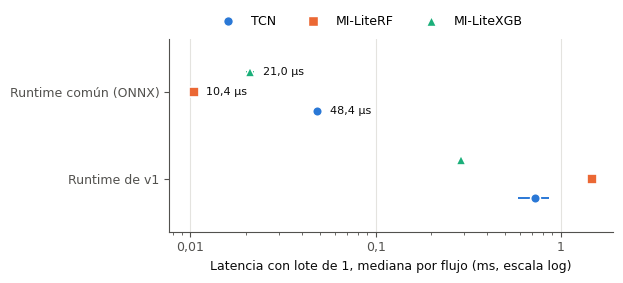

Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/M1_despliegue


In [ ]:
if correr('M1'):
    M1 = pd.DataFrame([f for r in REPS for f in RES_M1[r]['filas']])
    IND_M1 = ['tamano_archivo_kb', 'tamano_gzip_kb', 'memoria_pico_mb', 'memoria_total_mb', 'memoria_runtime_mb',
              'memoria_modelo_mb', 'latencia_ms_por_flujo', 'lote1_mediana_ms', 'lote1_p95_ms', 'respuesta_mediana_ms',
              'f1_macro', 'acuerdo_con_nativo']
    M1['orden'] = M1['modelo'].map({'tcn': 0, 'rf': 1, 'xgb': 2})
    R1 = M1.groupby(['orden', 'modelo', 'runtime'])[IND_M1].agg(['mean', 'std']).droplevel(0)
    vista_m1 = pd.DataFrame({c: [media_de(M1[(M1.modelo == m) & (M1.runtime == rt)][c].dropna()) if
                                 M1[(M1.modelo == m) & (M1.runtime == rt)][c].notna().any() else '—'
                                 for m, rt in R1.index] for c in IND_M1}, index=[f'{NOMBRE[m]} · {rt}' for m, rt in R1.index])
    display(vista_m1.T)

    # Contraste en el runtime común: MI-LiteRF vs. TCN (unilateral: el RF es menor), Holm sobre la familia
    comun = M1[~M1.runtime.str.startswith('Nativo')]
    t_c = comun[comun.modelo == 'tcn'].set_index('rep'); rf_c = comun[comun.modelo == 'rf'].set_index('rep')
    pr_m1 = []
    for ind in ['lote1_mediana_ms', 'respuesta_mediana_ms', 'latencia_ms_por_flujo', 'memoria_total_mb']:
        pr_m1.append({'indicador': ind, **prueba_pareada(t_c.loc[REPS, ind], rf_c.loc[REPS, ind], 'less')})
    PR_M1 = pd.DataFrame(pr_m1); PR_M1['p_holm'] = holm(PR_M1['p'])
    PR_M1['RF_menor'] = PR_M1['p_holm'] < ALFA
    display(PR_M1[['indicador', 'media_O1', 'media_O2', 'media_d', 'prueba', 'estadistico', 'p', 'p_holm', 'RF_menor']])

    # Reducción R (ec. 14.3) en el runtime común y comprimidos
    def R(tcn, rf):
        return (tcn - rf) / tcn * 100
    m_ = lambda d, c: d.loc[REPS, c].mean()
    nat = M1[M1.runtime.str.startswith('Nativo')]
    t_n, rf_n = nat[nat.modelo == 'tcn'].set_index('rep'), nat[nat.modelo == 'rf'].set_index('rep')
    RED_M1 = pd.DataFrame([
        {'comparación': 'Tamaño: .keras vs joblib (v1)', 'TCN': m_(t_n, 'tamano_archivo_kb'), 'MI-LiteRF': m_(rf_n, 'tamano_archivo_kb')},
        {'comparación': 'Tamaño: .keras vs joblib compress=3', 'TCN': m_(t_n, 'tamano_archivo_kb'), 'MI-LiteRF': m_(rf_n, 'tamano_joblib_c3_kb')},
        {'comparación': 'Tamaño: ONNX vs ONNX (runtime común)', 'TCN': m_(t_c, 'tamano_archivo_kb'), 'MI-LiteRF': m_(rf_c, 'tamano_archivo_kb')},
        {'comparación': 'Tamaño: ONNX gzip vs ONNX gzip', 'TCN': m_(t_c, 'tamano_gzip_kb'), 'MI-LiteRF': m_(rf_c, 'tamano_gzip_kb')},
        {'comparación': 'Memoria pico (def. v1), runtime común', 'TCN': m_(t_c, 'memoria_pico_mb'), 'MI-LiteRF': m_(rf_c, 'memoria_pico_mb')},
        {'comparación': 'Memoria total (runtime + modelo + inferencia), común', 'TCN': m_(t_c, 'memoria_total_mb'), 'MI-LiteRF': m_(rf_c, 'memoria_total_mb')},
        {'comparación': 'Memoria total, runtime de v1', 'TCN': m_(t_n, 'memoria_total_mb'), 'MI-LiteRF': m_(rf_n, 'memoria_total_mb')},
    ])
    RED_M1['R_%'] = R(RED_M1['TCN'], RED_M1['MI-LiteRF'])
    RED_M1['nivel'] = ['Crítico' if x < 25 else ('Aceptable' if x <= 75 else 'Óptimo') for x in RED_M1['R_%']]
    display(RED_M1.round(3))
    if (M1.metodo_conversion == 'tflite').any():
        print('⚠️ La TCN quedó en TFLite (plan B): el «runtime común» no es el mismo para los tres modelos.')

    # Figura M1 — latencia con lote de 1 (mediana por flujo), media ± DE de las REP
    fig, ax = plt.subplots(figsize=(6.3, 2.9))
    grupos = [('Nativo', 'Runtime de v1'), ('ONNX', 'Runtime común (ONNX)')]
    es_nativo = M1.runtime.str.startswith('Nativo')
    for g, (pref, etiqueta) in enumerate(grupos):
        for i, mod in enumerate(['tcn', 'rf', 'xgb']):
            d = M1[(M1.modelo == mod) & (es_nativo if pref == 'Nativo' else ~es_nativo)]
            if d.empty:
                continue
            yv = g + (i - 1) * 0.22
            m, s = d['lote1_mediana_ms'].mean(), d['lote1_mediana_ms'].std(ddof=1)
            ax.errorbar(m, yv, xerr=s if np.isfinite(s) else None, fmt=MARCA[mod], ms=7, color=COLOR[mod], mec='white',
                        mew=1.2, elinewidth=1.4, capsize=0, zorder=3)
            if pref == 'ONNX':
                ax.annotate(f'{m * 1000:,.1f} µs'.replace('.', ','), (m, yv), xytext=(9, 0), textcoords='offset points',
                            va='center', fontsize=8, color=TINTA)
    ax.set_xscale('log'); ax.set_yticks([0, 1]); ax.set_yticklabels([g[1] for g in grupos]); ax.set_ylim(-0.6, 1.6)
    ax.set_xlabel('Latencia con lote de 1, mediana por flujo (ms, escala log)')
    ax.xaxis.set_major_formatter(coma)
    ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color=REJILLA, lw=0.8); ax.set_axisbelow(True)
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([], [], ls='', marker=MARCA[m], ms=7, color=COLOR[m], mec='white', label=NOMBRE[m]) for m in ['tcn', 'rf', 'xgb']],
              frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.45, 1.0))
    fig.tight_layout(); fig.savefig(os.path.join(DIR_M1, 'fig_M1_latencia_lote1.png'), dpi=200); plt.show()

    with pd.ExcelWriter(os.path.join(DIR_M1, 'M1_resumen.xlsx')) as xw:
        vista_m1.T.to_excel(xw, sheet_name='Media ± DE')
        R1.to_excel(xw, sheet_name='Media y DE (valores)')
        RED_M1.to_excel(xw, sheet_name='Reducción R', index=False)
        PR_M1.to_excel(xw, sheet_name='Pruebas (RF < TCN)', index=False)
        M1.drop(columns='orden').to_excel(xw, sheet_name='Por REP', index=False)
    R1_plano = R1.copy(); R1_plano.columns = [f'{a}_{b}' for a, b in R1.columns]
    guardar_json({'resumen': R1_plano.reset_index().to_dict('records'), 'reduccion': RED_M1.to_dict('records'),
                  'pruebas': PR_M1.to_dict('records'), 'por_rep': M1.drop(columns='orden').to_dict('records')},
                 os.path.join(DIR_M1, 'M1_resultados.json'))
    print('Guardado en', DIR_M1)

## M2. Ablación (10 semillas; solo árboles)
Misma división, mismas semillas e hiperparámetros de v1 (k, T, RF árboles/profundidad de cada ficha). Cuatro brazos:
- **A0** — MI-LiteRF **reentrenado** con el mismo código (referencia). Debe salir idéntico al `rf.joblib` de v1; así los brazos solo difieren en el factor que se quita.
- **A1** — RF + balanceo con los **18 atributos de Gao** (aísla la selección por IM con el mismo clasificador).
- **A2** — RF + balanceo con los **95 atributos** (sin selección).
- **A3** — MI-LiteRF **sin balanceo** (aísla el balanceo).

La regla de lectura está fijada en la configuración (`MARGEN_RELEVANTE`). Nota: A0 usa k = 25 y A1 usa 18; la comparación con igual número de atributos la agrega M3 (v2 con k ≤ 18 frente a A1).

In [ ]:
DIR_M2 = os.path.join(DIR_MEJ, 'M2_ablacion')
BRAZOS = {'A0': 'MI-LiteRF reentrenado (referencia)',
          'A1': 'RF + balanceo, 18 atributos de Gao (sin IM)',
          'A2': 'RF + balanceo, 95 atributos (sin selección)',
          'A3': 'MI-LiteRF sin balanceo'}

def m2_rep(r):
    dir_r = os.path.join(DIR_M2, f'REP-{r:02d}')
    final = os.path.join(dir_r, 'M2_REP.json')
    if hay(final):
        return leer_json(final)
    t_ini = time.time()
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M2', D.codigo); os.makedirs(tmp, exist_ok=True)
    cols = {'A0': V.cols_k, 'A1': np.array(IDX_GAO), 'A2': np.arange(len(ATRIBUTOS)), 'A3': V.cols_k}
    balanceo = {'A0': True, 'A1': True, 'A2': True, 'A3': False}
    filas = []
    for b, desc in BRAZOS.items():
        sal_b = os.path.join(dir_r, f'brazo_{b}.json')
        if hay(sal_b):
            filas.append(leer_json(sal_b)); continue
        t0 = time.perf_counter()
        if balanceo[b]:
            Xb, yb = balancear(D.Xtr[:, cols[b]], D.ytr, V.T, D.semilla)
        else:
            Xb, yb = np.ascontiguousarray(D.Xtr[:, cols[b]]), D.ytr
        t_bal = time.perf_counter() - t0
        t0 = time.perf_counter()
        rf = RandomForestClassifier(V.rf[0], max_depth=V.rf[1], n_jobs=-1, random_state=D.semilla).fit(Xb, yb)
        t_ent = time.perf_counter() - t0
        ruta = os.path.join(tmp, f'rf_{b}.joblib'); joblib.dump(rf, ruta)
        x = guardar_x(os.path.join(tmp, f'x_{b}.npy'), D.Xte[:, cols[b]])
        m = medir('joblib', 'rf', ruta, x, os.path.join(tmp, f'medicion_{b}.json'))
        ind = indicadores(D.yte, m['pred'])
        fila = {'rep': r, 'brazo': b, 'descripcion': desc, 'n_atributos': int(len(cols[b])), 'balanceo': balanceo[b],
                'flujos_entrenamiento': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 2), 'tiempo_entrenamiento_s': round(t_ent, 2),
                'f1_macro': ind['f1_macro'], 'f1_por_clase': ind['f1_por_clase'], 'tfp': ind['tfp'],
                'falsas_alarmas': ind['falsas_alarmas'], 'exactitud': ind['exactitud'],
                'tamano_kb': m['tamano_archivo_kb'], 'tamano_c3_kb': kb_joblib(rf, 3),
                'latencia_ms': m['latencia_ms_por_flujo'], 'memoria_mb': m['memoria_pico_mb'],
                'nodos': int(sum(e.tree_.node_count for e in rf.estimators_)),
                'atributos': [ATRIBUTOS[j] for j in cols[b]] if b != 'A2' else 'los 95'}
        if b == 'A0':
            fila['identico_a_v1'] = bool(abs(ind['f1_macro'] - V.ind['rf']['f1_macro']) < 1e-9 and
                                         abs(m['tamano_archivo_kb'] - os.path.getsize(V.ruta_rf) / 1024) < 1.0)
        guardar_json(fila, sal_b); filas.append(fila)
        del rf, Xb, yb; gc.collect()
    res = {'rep': r, 'semilla': D.semilla, 'filas': filas, 'entorno': ENTORNO, 'segundos': round(time.time() - t_ini, 1)}
    guardar_json(res, final)
    bitacora('M2', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return res

In [ ]:
if correr('M2'):
    RES_M2 = {}
    for r in REPS:
        t0 = time.time()
        RES_M2[r] = m2_rep(r)
        F = {f['brazo']: f for f in RES_M2[r]['filas']}
        print(f"REP-{r:02d} | A0 idéntico a v1 {'✔' if F['A0'].get('identico_a_v1') else '⚠️'} | F1: " +
              ' | '.join(f"{b} {F[b]['f1_macro']:.2f}" for b in BRAZOS) + f' | {time.time() - t0:.0f} s')

REP-01 | A0 idéntico a v1 ✔ | F1: A0 90.09 | A1 84.31 | A2 90.09 | A3 93.28 | 1 s
REP-02 | A0 idéntico a v1 ✔ | F1: A0 90.50 | A1 85.00 | A2 89.71 | A3 93.14 | 1 s
REP-03 | A0 idéntico a v1 ✔ | F1: A0 90.32 | A1 84.57 | A2 89.98 | A3 93.43 | 1 s
REP-04 | A0 idéntico a v1 ✔ | F1: A0 90.47 | A1 85.06 | A2 90.23 | A3 93.33 | 1 s
REP-05 | A0 idéntico a v1 ✔ | F1: A0 90.30 | A1 84.91 | A2 89.89 | A3 93.34 | 1 s
REP-06 | A0 idéntico a v1 ✔ | F1: A0 90.32 | A1 84.86 | A2 89.72 | A3 93.12 | 41 s
REP-07 | A0 idéntico a v1 ✔ | F1: A0 90.31 | A1 84.88 | A2 89.88 | A3 93.11 | 40 s
REP-08 | A0 idéntico a v1 ✔ | F1: A0 90.24 | A1 84.68 | A2 89.96 | A3 93.12 | 39 s
REP-09 | A0 idéntico a v1 ✔ | F1: A0 90.25 | A1 84.80 | A2 90.13 | A3 93.27 | 39 s
REP-10 | A0 idéntico a v1 ✔ | F1: A0 90.38 | A1 84.72 | A2 89.84 | A3 93.30 | 38 s


,descripción,f1_macro,tfp,n_atributos,tamano_kb,tamano_c3_kb,latencia_ms,memoria_mb,tiempo_entrenamiento_s
A0,MI-LiteRF reentrenado (referencia),90.32 ± 0.12,0.0002688 ± 0.00085,25 ± 0,2925 ± 1.4e+02,459.7 ± 18,0.002855 ± 8.5e-05,4.807 ± 0.022,0.134 ± 0.007
A1,"RF + balanceo, 18 atributos de Gao (sin IM)",84.78 ± 0.22,0 ± 0,18 ± 0,2930 ± 1.7e+02,458.5 ± 21,0.002825 ± 7.8e-05,4.807 ± 0.02,0.118 ± 0.0079
A2,"RF + balanceo, 95 atributos (sin selección)",89.94 ± 0.17,0.0004399 ± 0.0014,95 ± 0,3218 ± 1.1e+02,501.1 ± 14,0.002929 ± 6.9e-05,4.805 ± 0.02,0.13 ± 0.012
A3,MI-LiteRF sin balanceo,93.24 ± 0.11,0 ± 0,25 ± 0,5504 ± 2.9e+02,896.6 ± 41,0.002953 ± 9e-05,4.802 ± 0.0076,4.501 ± 0.42


,brazo,F1 A0,F1 brazo,Δ = A0 − brazo,ic95_d,prueba,estadistico,p,p_holm,lectura,significado
0,A1,90.317407,84.778145,5.539262,"(5.436737506649085, 5.641787084962673)",t pareada,122.220996,8.346192e-16,2.503857e-15,A favor de MI-LiteRF,La selección por IM aporta frente a la de Gao ...
1,A2,90.317407,89.943168,0.374240,"(0.2065225587985392, 0.541956518368082)",t pareada,5.047722,6.924834e-04,6.924834e-04,Sin diferencia relevante,La IM reduce de 95 a k atributos sin perder F1...
2,A3,90.317407,93.243750,-2.926343,"(-3.044802115039659, -2.8078836013366035)",t pareada,-55.882906,9.467756e-13,1.893551e-12,En contra de MI-LiteRF,Sin balanceo se obtiene más F1 macro.


brazo,A1,A2,A3
clase,,,
Backdoor,0.04,0.09,-0.53
DDoS_HTTP,4.60,0.97,-1.40
DDoS_ICMP,-0.02,-0.02,-0.22
DDoS_TCP,14.55,0.01,-0.00
DDoS_UDP,-0.01,-0.01,-0.02
Fingerprinting,3.73,0.44,-33.81
MITM,-1.23,-0.68,-1.23
Normal,-0.00,0.00,-0.00
Password,3.44,0.25,-0.31


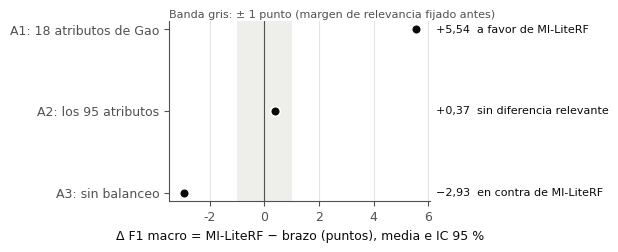

Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/M2_ablacion


In [ ]:
if correr('M2'):
    M2 = pd.DataFrame([f for r in REPS for f in RES_M2[r]['filas']])
    if not M2.loc[M2.brazo == 'A0', 'identico_a_v1'].all():
        print('⚠️ A0 no reproduce exactamente el rf.joblib de v1 en alguna REP: la referencia es A0 (mismo código y sesión).')
    cols_t = ['f1_macro', 'tfp', 'n_atributos', 'tamano_kb', 'tamano_c3_kb', 'latencia_ms', 'memoria_mb', 'tiempo_entrenamiento_s']
    vista_m2 = pd.DataFrame({b: {c: media_de(M2[M2.brazo == b][c]) for c in cols_t} for b in BRAZOS}).T
    vista_m2.insert(0, 'descripción', [BRAZOS[b] for b in vista_m2.index])
    display(vista_m2)

    # F1 macro: d = A0 − brazo (bilateral), Holm sobre los 3 brazos; lectura con el margen fijado
    piv = M2.pivot(index='rep', columns='brazo', values='f1_macro').loc[REPS]
    pr = [{'brazo': b, **prueba_pareada(piv[b], piv['A0'], 'two-sided')} for b in ['A1', 'A2', 'A3']]
    PR_M2 = pd.DataFrame(pr); PR_M2['p_holm'] = holm(PR_M2['p'])
    def lectura(fila):
        if fila.p_holm < ALFA and fila.media_d >= MARGEN_RELEVANTE:
            return 'A favor de MI-LiteRF'
        if fila.p_holm < ALFA and fila.media_d <= -MARGEN_RELEVANTE:
            return 'En contra de MI-LiteRF'
        return 'Sin diferencia relevante'
    PR_M2['lectura'] = PR_M2.apply(lectura, axis=1)
    SIGNIFICADO = {
        ('A1', 'A favor de MI-LiteRF'): 'La selección por IM aporta frente a la de Gao con el mismo RF y balanceo → «basado en entropía» respaldado.',
        ('A1', 'Sin diferencia relevante'): 'La ganancia viene del RF + balanceo, no de la IM → reformular «basado en entropía» (escenario D).',
        ('A1', 'En contra de MI-LiteRF'): 'Los 18 de Gao rinden más que la IM con el mismo RF → la IM no se sostiene (escenario D).',
        ('A2', 'A favor de MI-LiteRF'): 'Seleccionar con IM mejora frente a usar los 95 atributos.',
        ('A2', 'Sin diferencia relevante'): 'La IM reduce de 95 a k atributos sin perder F1 relevante.',
        ('A2', 'En contra de MI-LiteRF'): 'La selección por IM cuesta F1 frente a usar los 95 atributos.',
        ('A3', 'A favor de MI-LiteRF'): 'El balanceo aporta a la ganancia.',
        ('A3', 'Sin diferencia relevante'): 'El balanceo no aporta una diferencia relevante.',
        ('A3', 'En contra de MI-LiteRF'): 'Sin balanceo se obtiene más F1 macro.'}
    PR_M2['significado'] = [SIGNIFICADO[(b, l)] for b, l in zip(PR_M2.brazo, PR_M2.lectura)]
    display(PR_M2[['brazo', 'media_O2', 'media_O1', 'media_d', 'ic95_d', 'prueba', 'estadistico', 'p', 'p_holm', 'lectura', 'significado']]
            .rename(columns={'media_O2': 'F1 A0', 'media_O1': 'F1 brazo', 'media_d': 'Δ = A0 − brazo'}))

    # F1 por clase: Holm dentro de cada brazo (15 clases)
    filas_c = []
    for b in ['A1', 'A2', 'A3']:
        bloque = []
        for c in CLASES:
            a0 = [f['f1_por_clase'][c] for f in M2[M2.brazo == 'A0'].sort_values('rep').to_dict('records')]
            ab = [f['f1_por_clase'][c] for f in M2[M2.brazo == b].sort_values('rep').to_dict('records')]
            bloque.append({'brazo': b, 'clase': c, **prueba_pareada(ab, a0, 'two-sided')})
        ph = holm([x['p'] for x in bloque])
        for x, p in zip(bloque, ph):
            x['p_holm'] = p
        filas_c += bloque
    PC_M2 = pd.DataFrame(filas_c)[['brazo', 'clase', 'media_O2', 'media_O1', 'media_d', 'prueba', 'p', 'p_holm']] \
              .rename(columns={'media_O2': 'F1 A0', 'media_O1': 'F1 brazo', 'media_d': 'Δ = A0 − brazo'})
    display(PC_M2.pivot(index='clase', columns='brazo', values='Δ = A0 − brazo').round(2))

    # Figura M2 — Δ F1 macro con IC 95 %
    fig, ax = plt.subplots(figsize=(6.3, 2.6))
    ax.axvspan(-MARGEN_RELEVANTE, MARGEN_RELEVANTE, color=REJILLA, alpha=0.6, lw=0)
    ax.axvline(0, color=TINTA2, lw=0.8)
    for i, f in enumerate(PR_M2.itertuples()):
        lo, hi = f.ic95_d
        if np.isfinite(lo):
            ax.hlines(i, lo, hi, color=TINTA, lw=1.4)
        ax.plot(f.media_d, i, 'o', ms=7, color=TINTA, mec='white', mew=1.2, zorder=3)
        ax.text(1.02, i, f'{f.media_d:+.2f}'.replace('.', ',').replace('-', '−') + f'  {f.lectura[0].lower() + f.lectura[1:]}',
                transform=ax.get_yaxis_transform(), va='center', fontsize=8, color=TINTA)
    CORTO = {'A1': 'A1: 18 atributos de Gao', 'A2': f'A2: los {len(ATRIBUTOS)} atributos', 'A3': 'A3: sin balanceo'}
    ax.set_yticks(range(len(PR_M2))); ax.set_yticklabels([CORTO[b] for b in PR_M2.brazo])
    ax.invert_yaxis(); ax.xaxis.set_major_formatter(coma)
    ax.set_xlabel('Δ F1 macro = MI-LiteRF − brazo (puntos), media e IC 95 %')
    ax.text(0, 1.02, f'Banda gris: ± {MARGEN_RELEVANTE:g} punto (margen de relevancia fijado antes)'.replace('.', ','),
            transform=ax.transAxes, fontsize=8, color=TINTA2)
    ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color=REJILLA, lw=0.8); ax.set_axisbelow(True)
    x0, x1 = ax.get_xlim(); ax.set_xlim(min(x0, -MARGEN_RELEVANTE * 1.5), max(x1, MARGEN_RELEVANTE * 1.5))
    fig.tight_layout(); fig.savefig(os.path.join(DIR_M2, 'fig_M2_ablacion_f1.png'), dpi=200, bbox_inches='tight'); plt.show()

    with pd.ExcelWriter(os.path.join(DIR_M2, 'M2_resumen.xlsx')) as xw:
        vista_m2.to_excel(xw, sheet_name='Media ± DE')
        PR_M2.astype({'ic95_d': str}).to_excel(xw, sheet_name='F1 macro (Holm)', index=False)
        PC_M2.to_excel(xw, sheet_name='F1 por clase (Holm)', index=False)
        M2.drop(columns=['f1_por_clase']).astype({'atributos': str}).to_excel(xw, sheet_name='Por REP', index=False)
    guardar_json({'vista': vista_m2.reset_index().to_dict('records'), 'pruebas_f1_macro': PR_M2.to_dict('records'),
                  'pruebas_por_clase': PC_M2.to_dict('records'), 'por_rep': M2.to_dict('records'),
                  'margen_relevante': MARGEN_RELEVANTE}, os.path.join(DIR_M2, 'M2_resultados.json'))
    print('Guardado en', DIR_M2)

## M3. MI-LiteRF v2 compacto (curva de Pareto)
CV de 3 pliegues **solo en el entrenamiento** (balanceo dentro de cada pliegue, como v1) sobre la rejilla k × profundidad × árboles; en cada combinación se registran el F1 macro de CV, el tamaño (joblib sin comprimir y con `compress=3`) y el número de nodos. La regla elige **una** configuración por REP; luego se entrena en el entrenamiento completo, se mide junto a la TCN y MI-LiteXGB de v1 en la misma sesión, se generan las fichas v2 y se reconsolida.

**Regla aprobada el 16/11/2026 (opción B).** La celda siguiente la imprime con los valores de la configuración; si `REGLA_M3_APROBADA = False`, esta parte no corre.

In [ ]:
def texto_regla_m3():
    ranking = (f'información mutua de v1 + descarte de redundantes: se recorre el ranking de IM y se omite un atributo si su '
               f'incertidumbre simétrica SU = 2·I(Xi;Xj)/(H(Xi)+H(Xj)) con alguno ya elegido es ≥ {M3_TAU_SU:.2f}'
               if M3_FILTRO_SU else 'información mutua de v1, sin filtro (los k primeros del ranking)')
    criterio = 'joblib sin comprimir (el indicador de la tabla 14.3)' if M3_CRITERIO_TAMANO == 'tamano_kb' else 'joblib con compress=3'
    return f"""REGLA DE SELECCIÓN DE M3 (se fija antes de mirar el conjunto de prueba)
 1. Ranking de atributos: {ranking}. Todo se calcula con el entrenamiento de la REP (submuestra estratificada de {MI_SUBMUESTRA:,} flujos, como v1).
 2. Rejilla: k ∈ {M3_K_GRID} × profundidad ∈ {M3_PROF_GRID} × árboles ∈ {M3_ARBOLES_GRID}; balanceo T = {M3_T:,}.
    CV estratificada de 3 pliegues en el entrenamiento de {'cada REP (como v1)' if M3_CV_POR_REP else 'REP-01 (la elección se aplica a las 10)'}.
 3. Candidatos: F1 macro de CV ≥ {M3_TOLERANCIA * 100:.0f} % del mejor de toda la rejilla Y k ≤ {M3_K_MAX}.
 4. Elegido: el candidato de menor tamaño ({criterio}). Empates: menor k y luego mayor F1 de CV.
 5. Respaldo fijado: si ningún candidato tiene k ≤ {M3_K_MAX}, se elige el de menor tamaño con F1 ≥ {M3_TOLERANCIA * 100:.0f} % del mejor
    sin límite de k, y se informa que la dimensión «atributos» no mejora.
 6. MI-LiteXGB y la TCN no cambian (v1); se re-miden en la misma sesión.
 Estado: {'✅ APROBADA' if REGLA_M3_APROBADA else '🔒 PENDIENTE DE APROBACIÓN'}"""
print(texto_regla_m3())

REGLA DE SELECCIÓN DE M3 (se fija antes de mirar el conjunto de prueba)
 1. Ranking de atributos: información mutua de v1 + descarte de redundantes: se recorre el ranking de IM y se omite un atributo si su incertidumbre simétrica SU = 2·I(Xi;Xj)/(H(Xi)+H(Xj)) con alguno ya elegido es ≥ 0.99. Todo se calcula con el entrenamiento de la REP (submuestra estratificada de 200,000 flujos, como v1).
 2. Rejilla: k ∈ [10, 15, 18, 20, 25] × profundidad ∈ [8, 10, 12, 15] × árboles ∈ [10, 15, 25]; balanceo T = 2,000.
    CV estratificada de 3 pliegues en el entrenamiento de cada REP (como v1).
 3. Candidatos: F1 macro de CV ≥ 99 % del mejor de toda la rejilla Y k ≤ 18.
 4. Elegido: el candidato de menor tamaño (joblib sin comprimir (el indicador de la tabla 14.3)). Empates: menor k y luego mayor F1 de CV.
 5. Respaldo fijado: si ningún candidato tiene k ≤ 18, se elige el de menor tamaño con F1 ≥ 99 % del mejor
    sin límite de k, y se informa que la dimensión «atributos» no mejora.
 6. MI-LiteXGB

In [ ]:
DIR_M3 = os.path.join(DIR_MEJ, 'M3_v2')

def ranking_im(D, atributos, su=False, tau=None, k_max=None):
    """IM de v1 (misma submuestra y discretización). Con su=True recorre el ranking y omite redundantes (SU ≥ tau)."""
    tau = M3_TAU_SU if tau is None else tau
    k_max = max(M3_K_GRID) if k_max is None else k_max
    if len(D.ytr) > MI_SUBMUESTRA:
        sub, _ = train_test_split(np.arange(len(D.ytr)), train_size=MI_SUBMUESTRA, stratify=D.ytr, random_state=D.semilla)
    else:
        sub = np.arange(len(D.ytr))
    Ys = D.ytr[sub]; HY = entropia(Ys)
    disc, filas = {}, []
    for j, nombre in enumerate(atributos):
        xc = discretizar(D.Xtr[sub, j]); disc[j] = xc
        HX = entropia(xc)
        filas.append((nombre, j, HX, HY + HX - entropia(Ys, xc)))
    mi = pd.DataFrame(filas, columns=['atributo', 'indice', 'H_X_bits', 'IM_bits']) \
           .sort_values('IM_bits', ascending=False, kind='mergesort').reset_index(drop=True)
    mi.insert(0, 'rango', np.arange(1, len(mi) + 1))
    if not su:
        return mi, mi['indice'].to_numpy()
    H = dict(zip(mi['indice'], mi['H_X_bits']))
    elegidos, red_con, su_max_l = [], [], []
    for j in mi['indice']:
        if len(elegidos) >= k_max:
            red_con.append('no evaluado'); su_max_l.append(np.nan); continue
        su_max, con = 0.0, None
        for s in elegidos:
            den = H[j] + H[s]
            su_js = 1.0 if den == 0 else 2 * (H[j] + H[s] - entropia(disc[j], disc[s])) / den
            if su_js > su_max:
                su_max, con = su_js, s
            if su_max >= tau:
                break
        su_max_l.append(su_max)
        if su_max >= tau:
            red_con.append(atributos[con])
        else:
            elegidos.append(j); red_con.append('')
    mi['SU_max_con_elegidos'] = su_max_l
    mi['redundante_con'] = red_con
    mi['elegido_v2'] = mi['indice'].isin(elegidos)
    return mi, np.array(elegidos)

def cv_m3(D, orden):
    pliegues = list(StratifiedKFold(3, shuffle=True, random_state=D.semilla).split(np.zeros(len(D.ytr)), D.ytr))
    acc = {}
    for k in M3_K_GRID:
        cols = orden[:k]
        for f, (a_, b_) in enumerate(pliegues):
            Xb, yb = balancear(D.Xtr[np.ix_(a_, cols)], D.ytr[a_], M3_T, D.semilla + f)   # semilla + pliegue, como v1
            Xv, yv = D.Xtr[np.ix_(b_, cols)], D.ytr[b_]
            for prof in M3_PROF_GRID:
                for n in M3_ARBOLES_GRID:
                    m = RandomForestClassifier(n, max_depth=prof, n_jobs=-1, random_state=D.semilla).fit(Xb, yb)
                    v = acc.setdefault((k, prof, n), {'f1': [], 'kb': [], 'kb_c3': [], 'nodos': []})
                    v['f1'].append(f1_macro(yv, m.predict(Xv)))
                    v['kb'].append(kb_joblib(m)); v['kb_c3'].append(kb_joblib(m, 3))
                    v['nodos'].append(sum(e.tree_.node_count for e in m.estimators_))
            del Xb, yb, Xv
        print(f'   k = {k}: listo')
    return pd.DataFrame([{'k': k, 'profundidad': p, 'arboles': n, 'f1_macro_cv': np.mean(v['f1']), 'f1_de': np.std(v['f1'], ddof=1),
                          'tamano_kb': np.mean(v['kb']), 'tamano_c3_kb': np.mean(v['kb_c3']), 'nodos': np.mean(v['nodos'])}
                         for (k, p, n), v in acc.items()])

def regla_m3(tabla):
    tabla = tabla.copy()
    mejor = tabla['f1_macro_cv'].max()
    tabla['cumple_f1'] = tabla['f1_macro_cv'] >= M3_TOLERANCIA * mejor
    tabla['cumple_k'] = tabla['k'] <= M3_K_MAX
    cand = tabla[tabla.cumple_f1 & tabla.cumple_k]
    cumple_k = len(cand) > 0
    if not cumple_k:
        cand = tabla[tabla.cumple_f1]
    el = cand.sort_values([M3_CRITERIO_TAMANO, 'k', 'f1_macro_cv'], ascending=[True, True, False], kind='mergesort').iloc[0]
    tabla['elegido'] = (tabla.k == el.k) & (tabla.profundidad == el.profundidad) & (tabla.arboles == el.arboles)
    return tabla, {'k': int(el.k), 'profundidad': int(el.profundidad), 'arboles': int(el.arboles),
                   'f1_macro_cv': float(el.f1_macro_cv), 'mejor_f1_cv': float(mejor), 'umbral_f1_cv': float(M3_TOLERANCIA * mejor),
                   'tamano_kb_cv': float(el.tamano_kb), 'tamano_c3_kb_cv': float(el.tamano_c3_kb),
                   'cumple_k_max': bool(cumple_k), 'regla': texto_regla_m3()}

def m3_rep(r, eleccion_global=None):
    dir_r = os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M3', D.codigo); os.makedirs(tmp, exist_ok=True)

    # 1) Ranking (IM de v1 + filtro SU si aplica). Se verifica que la IM recalculada sea la de v1.
    ruta_rank = os.path.join(dir_r, 'ranking_v2.csv')
    if hay(ruta_rank):
        rank = pd.read_csv(ruta_rank)
        orden = rank.loc[rank['elegido_v2'], 'indice'].to_numpy() if M3_FILTRO_SU else rank['indice'].to_numpy()
    else:
        rank, orden = ranking_im(D, ATRIBUTOS, su=M3_FILTRO_SU)
        if not np.array_equal(rank['indice'].to_numpy(), V.orden_mi):
            print(f'⚠️ {D.codigo}: el ranking de IM recalculado no es idéntico al de v1 (se usa el recalculado).')
        rank.to_csv(ruta_rank, index=False)
    V.mi.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)   # la consolidación lo usa en la sección del artefacto

    # 2) CV y regla
    t_cv = time.perf_counter()
    if M3_CV_POR_REP or eleccion_global is None:
        ruta_cv = os.path.join(dir_r, 'cv_m3.csv')
        tabla = pd.read_csv(ruta_cv) if hay(ruta_cv) else cv_m3(D, orden)
        tabla, eleccion = regla_m3(tabla)
        tabla.to_csv(ruta_cv, index=False)
    else:
        eleccion = eleccion_global
    t_cv = time.perf_counter() - t_cv
    guardar_json(eleccion, os.path.join(dir_r, 'seleccion_m3.json'))
    k2, p2, n2 = eleccion['k'], eleccion['profundidad'], eleccion['arboles']
    cols2 = orden[:k2]

    # 3) Entrenamiento final v2 (entrenamiento completo, balanceado con la semilla de la REP)
    t0 = time.perf_counter()
    Xb, yb = balancear(D.Xtr[:, cols2], D.ytr, M3_T, D.semilla)
    t_bal = time.perf_counter() - t0; t0 = time.perf_counter()
    rf2 = RandomForestClassifier(n2, max_depth=p2, n_jobs=-1, random_state=D.semilla).fit(Xb, yb)
    t_ent = time.perf_counter() - t0
    ruta_rf2 = os.path.join(dir_r, 'rf_v2.joblib'); joblib.dump(rf2, ruta_rf2)
    ruta_rf2_onnx = a_onnx_arbol(rf2, 'rf', k2, os.path.join(dir_r, 'rf_v2.onnx'))
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1),
               'tiempo_entrenamiento_rf_s': round(t_ent, 2), 'tamano_c3_kb': kb_joblib(rf2, 3),
               'nodos': int(sum(e.tree_.node_count for e in rf2.estimators_))}
    del Xb, yb, rf2

    # 4) Medición en la misma sesión (lote de 1 024 como v1) + runtime común con lote de 1
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf2, D.Xte[:, cols2], V.ruta_xgb, D.Xte[:, V.cols_k])
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    ruta_tcn_onnx = os.path.join(DIR_M1, f'REP-{r:02d}', 'tcn.onnx')
    if not os.path.exists(ruta_tcn_onnx):
        ruta_tcn_onnx, _ = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if ruta_tcn_onnx.endswith('.tflite') else 'onnx'
    comun = {}
    for tipo, fmt, ruta, cols, xs in [('tcn', fmt_tcn, ruta_tcn_onnx, IDX_GAO, 'x_tcn.npy'), ('rf', 'onnx', ruta_rf2_onnx, cols2, 'x_rf.npy')]:
        x1 = lote1_npz(os.path.join(tmp, f'x1_{tipo}.npz'), D, sub, cols)
        m = medir(fmt, tipo, ruta, os.path.join(tmp, xs), os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'),
                  n1=M1_N_LOTE1, x1=x1, respuesta=True)
        comun[tipo] = {k: v for k, v in m.items() if k != 'pred'}
        comun[tipo].update(f1_macro=f1_macro(D.yte, m['pred']), tamano_gzip_kb=kb_gzip(ruta))

    # 5) Ficha v2 (misma estructura que v1)
    sel = {'k': k2, 'T': M3_T, 'rf_arboles': n2, 'rf_profundidad': p2, 'xgb_arboles': V.xgb[0], 'xgb_profundidad': V.xgb[1],
           'xgb_lr': V.xgb_lr, 'atributos_k': [ATRIBUTOS[j] for j in cols2], 'tiempo_cv_s': round(t_cv, 1),
           'filtro_su': M3_FILTRO_SU, 'tau_su': M3_TAU_SU, 'eleccion': eleccion}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_cv / 60,
               'entrenamiento_rf_s': t_ent, 'entrenamiento_xgb_s': V.ficha['tiempos']['entrenamiento_xgb_s']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': k2, 'xgb': V.K}, sel, finales, tiempos,
                            'v2 (M3: MI-LiteRF compacto)', V.ficha['preprocesamiento'], len(ATRIBUTOS))
    ficha['runtime_comun'] = comun
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01,
                        'xgb_f1_igual_v1': abs(res['xgb']['f1_macro'] - V.ind['xgb']['f1_macro']) < 1e-6}
    guardar_json(ficha, ruta_ficha)
    bitacora('M3', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return ficha

In [ ]:
# Vista previa para aprobar la regla: usa SOLO el entrenamiento de la primera REP (no toca la prueba)
if M3_VISTA_PREVIA:
    _D, _V = dividir(REPS[0]), v1(REPS[0])
    _rank, _orden = ranking_im(_D, ATRIBUTOS, su=True)
    os.makedirs(DIR_M3, exist_ok=True)
    _rank.to_csv(os.path.join(DIR_M3, f'vista_previa_ranking_{_D.codigo}.csv'), index=False)
    _k = min(M3_K_MAX, len(_orden))
    _sel = {ATRIBUTOS[j] for j in _orden[:_k]}
    _red = dict(zip(_rank['atributo'], _rank['redundante_con']))
    _v1 = [ATRIBUTOS[j] for j in _V.cols_k]
    _cubiertos = [a for a in _v1 if a in _sel or _red.get(a) in _sel]
    print(f'Vista previa {_D.codigo} (solo entrenamiento, SU ≥ {M3_TAU_SU}):')
    print(f'  · De los {len(_v1)} atributos de MI-LiteRF v1, {sum(bool(_red.get(a)) for a in _v1)} son redundantes con otro ya elegido.')
    print(f'  · Con el filtro, k = {_k} cubre {len(_cubiertos)} de los {len(_v1)} de v1 (elegidos o redundantes con uno elegido).')
    print(f'  · k = {_k} con filtro:', ', '.join(ATRIBUTOS[j] for j in _orden[:_k]))
    display(_rank.head(40)[['rango', 'atributo', 'H_X_bits', 'IM_bits', 'SU_max_con_elegidos', 'redundante_con', 'elegido_v2']].round(4))
    del _D; gc.collect()

Vista previa REP-01 (solo entrenamiento, SU ≥ 0.99):
  · De los 25 atributos de MI-LiteRF v1, 6 son redundantes con otro ya elegido.
  · Con el filtro, k = 18 cubre 24 de los 25 de v1 (elegidos o redundantes con uno elegido).
  · k = 18 con filtro: mqtt.conack.flags-0.0, dns.qry.name.len-0, tcp.ack, tcp.flags, mqtt.protoname-0, mqtt.conack.flags-0, mqtt.topic-0, tcp.seq, http.request.version-0.0, http.request.version-0, tcp.ack_raw, tcp.checksum, tcp.flags.ack, http.referer-0.0, udp.stream, tcp.len, icmp.checksum, icmp.seq_le


,rango,atributo,H_X_bits,IM_bits,SU_max_con_elegidos,redundante_con,elegido_v2
0,1,mqtt.conack.flags-0.0,0.8632,0.8632,0.0000,,True
1,2,mqtt.protoname-0.0,0.8632,0.8632,1.0000,mqtt.conack.flags-0.0,False
2,3,mqtt.topic-0.0,0.8632,0.8632,1.0000,mqtt.conack.flags-0.0,False
3,4,dns.qry.name.len-0.0,0.8630,0.8628,0.9983,mqtt.conack.flags-0.0,False
4,5,dns.qry.name.len-0,0.8644,0.8540,0.9887,,True
5,6,tcp.ack,3.5750,0.8166,0.1856,,True
6,7,tcp.flags,2.4959,0.7019,0.4473,,True
7,8,mqtt.protoname-0,0.9135,0.6797,0.7651,,True
8,9,mqtt.conack.flags-0,0.9141,0.6779,0.7628,,True
9,10,mqtt.topic-0,0.9144,0.6770,0.7618,,True


In [ ]:
if correr('M3'):
    print(texto_regla_m3()); print()
    FICHAS_M3, eleccion_global = {}, None
    for r in REPS:
        t0 = time.time()
        FICHAS_M3[r] = m3_rep(r, eleccion_global)
        e = FICHAS_M3[r]['seleccion']['eleccion']
        if not M3_CV_POR_REP and eleccion_global is None:
            eleccion_global = e
        f = {x['Indicador (unidad)']: x for x in FICHAS_M3[r]['tabla_14_3']}
        print(f"REP-{r:02d} | k = {e['k']}, prof = {e['profundidad']}, árboles = {e['arboles']} "
              f"(F1 CV {e['f1_macro_cv']:.2f} ≥ {e['umbral_f1_cv']:.2f}; k ≤ {M3_K_MAX}: {'sí' if e['cumple_k_max'] else 'NO → respaldo'}) | "
              f"F1 prueba {f['Puntaje F1 macro (%)']['O2 RF']:.2f} | {f['Tamaño del modelo serializado (KB)']['O2 RF']:,.0f} KB | "
              f"controles {'✔' if all(FICHAS_M3[r]['control'].values()) else '⚠️'} | {time.time() - t0:.0f} s")
    C_M3 = consolidar(DIR_M3, 'M3_v2')

REGLA DE SELECCIÓN DE M3 (se fija antes de mirar el conjunto de prueba)
 1. Ranking de atributos: información mutua de v1 + descarte de redundantes: se recorre el ranking de IM y se omite un atributo si su incertidumbre simétrica SU = 2·I(Xi;Xj)/(H(Xi)+H(Xj)) con alguno ya elegido es ≥ 0.99. Todo se calcula con el entrenamiento de la REP (submuestra estratificada de 200,000 flujos, como v1).
 2. Rejilla: k ∈ [10, 15, 18, 20, 25] × profundidad ∈ [8, 10, 12, 15] × árboles ∈ [10, 15, 25]; balanceo T = 2,000.
    CV estratificada de 3 pliegues en el entrenamiento de cada REP (como v1).
 3. Candidatos: F1 macro de CV ≥ 99 % del mejor de toda la rejilla Y k ≤ 18.
 4. Elegido: el candidato de menor tamaño (joblib sin comprimir (el indicador de la tabla 14.3)). Empates: menor k y luego mayor F1 de CV.
 5. Respaldo fijado: si ningún candidato tiene k ≤ 18, se elige el de menor tamaño con F1 ≥ 99 % del mejor
    sin límite de k, y se informa que la dimensión «atributos» no mejora.
 6. MI-LiteXGB

,k,profundidad,arboles,cumple_k_max,f1_cv,f1_v2,f1_tcn,tamano_v2_kb,tamano_v2_c3_kb,tamano_v2_onnx_kb,...,latencia_v2_ms,latencia_tcn_ms,lote1_v2_ms,lote1_tcn_ms,respuesta_v2_ms,respuesta_tcn_ms,memoria_v2_mb,memoria_tcn_mb,tfp_v2,f1_v1
rep,,,,,,,,,,,,,,,,,,,,,
1,18,15,10,True,90.0041,89.9873,68.4550,989.8604,163.1982,647.4844,...,0.0013,0.0017,0.0093,0.0493,0.0217,0.0651,4.8242,124.2969,0.0000,90.0906
2,25,12,10,False,89.7212,88.7004,68.9383,570.4697,107.8867,366.8945,...,0.0013,0.0020,0.0090,0.0513,0.0176,0.0650,4.9453,123.1289,0.0560,90.5039
3,20,12,15,False,89.4897,89.5084,69.8563,789.8135,149.6494,506.6787,...,0.0020,0.0021,0.0106,0.0505,0.0200,0.0618,4.9258,122.1055,0.0024,90.3179
4,18,12,10,True,89.6014,89.3394,68.3053,555.0166,106.0195,356.6084,...,0.0014,0.0025,0.0094,0.0468,0.0175,0.0610,4.9414,122.3008,0.0000,90.4694
5,25,15,10,False,90.2062,90.1869,68.8086,1232.0791,195.1328,809.4492,...,0.0014,0.0027,0.0095,0.0453,0.0180,0.0607,4.8047,121.9766,0.0000,90.2995
6,18,15,10,True,90.1013,90.1389,68.8768,1239.2666,189.8877,814.1514,...,0.0014,0.0015,0.0090,0.0506,0.0173,0.0657,4.8086,123.0195,0.0000,90.3156
7,20,15,10,False,90.3748,89.6658,68.3797,1245.7354,192.9209,818.5342,...,0.0014,0.0027,0.0096,0.0497,0.0179,0.0626,4.8164,119.0781,0.0000,90.3109
8,20,15,10,False,90.2309,89.8650,66.9260,1140.4385,181.6260,748.1436,...,0.0018,0.0033,0.0096,0.0505,0.0190,0.0644,4.8242,122.7617,0.0000,90.2404
9,20,12,10,False,90.1172,89.6543,68.4976,557.8916,105.6416,358.5010,...,0.0014,0.0031,0.0116,0.0484,0.0208,0.0650,4.9414,124.1992,0.0000,90.2469


Atributos v2 (REP-01): mqtt.conack.flags-0.0, dns.qry.name.len-0, tcp.ack, tcp.flags, mqtt.protoname-0, mqtt.conack.flags-0, mqtt.topic-0, tcp.seq, http.request.version-0.0, http.request.version-0, tcp.ack_raw, tcp.checksum, tcp.flags.ack, http.referer-0.0, udp.stream, tcp.len, icmp.checksum, icmp.seq_le


,comparación,media_O1,media_O2,media_d,ic95_d,prueba,p,p_holm
0,MI-LiteRF v2 − v1 (F1 macro),90.317407,89.729391,-0.588016,"(-0.9803433087889775, -0.19568874315268342)",t pareada,7.992797e-03,7.992797e-03
1,MI-LiteRF v2 − TCN (F1 macro),68.529980,89.729391,21.199411,"(20.51258932005432, 21.886232484521)",t pareada,1.281063e-13,3.843188e-13
2,"MI-LiteRF v2 − A1 (18 de Gao, mismo RF + balan...",84.778145,89.729391,4.951246,"(4.525480221890667, 5.377012317779431)",t pareada,8.004161e-10,1.600832e-09


— Consolidación v2 (tabla 14.6 y veredictos con MI-LiteRF v2) —


,Hipótesis,Veredicto,Sustento
0,H.E. 1 (exactitud: F1 macro),Respaldada,"t pareada, p Holm = < 0,001"
1,H.E. 2 (latencia de detección: inferencia y re...,No evaluable,"Latencia: Respaldada (t pareada, p Holm = < 0,..."
2,H.E. 3 (TFP),No respaldada,"Wilcoxon (rangos con signo), p Holm = 1,000"
3,H.G. (detección temprana de anomalías),No respaldada,Requiere las tres específicas; se sostienen: H...


,Indicador (unidad),tcn_media,rf_media,xgb_media,valor_pct,nivel_RF
0,Pico de memoria RAM (MB),122.3684,4.8668,5.3996,96.0228,Óptimo
1,Tamaño del modelo serializado (KB),166.4492,950.2697,781.3859,-470.9067,Crítico
2,Número de atributos (n.º),18.0000,20.9000,25.0000,78.0000,Óptimo
3,Puntaje F1 macro (%),68.5300,89.7294,90.0226,30.9345,Óptimo
4,Latencia de inferencia (ms/muestra),0.0024,0.0015,0.0070,-38.3800,Óptimo
5,Retardo de detección (ms; mediana),NaN,NaN,NaN,NaN,No calculable
6,"Proporción de falsas alarmas, TFP (%)",0.0000,0.0058,0.0000,11850.0000,Óptimo


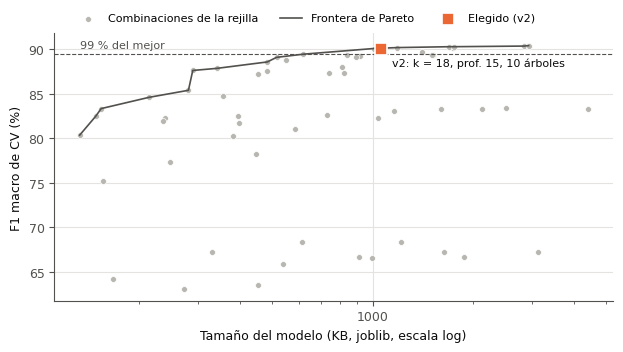

Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/M3_v2


In [ ]:
if correr('M3'):
    filas = []
    for r in REPS:
        F = FICHAS_M3[r]; t = {x['Indicador (unidad)']: x for x in F['tabla_14_3']}; e = F['seleccion']['eleccion']
        filas.append({'rep': r, 'k': e['k'], 'profundidad': e['profundidad'], 'arboles': e['arboles'], 'cumple_k_max': e['cumple_k_max'],
                      'f1_cv': e['f1_macro_cv'], 'f1_v2': t['Puntaje F1 macro (%)']['O2 RF'],
                      'f1_tcn': t['Puntaje F1 macro (%)']['O1 TCN'],
                      'tamano_v2_kb': t['Tamaño del modelo serializado (KB)']['O2 RF'],
                      'tamano_v2_c3_kb': F['finales']['tamano_c3_kb'],
                      'tamano_v2_onnx_kb': F['runtime_comun']['rf']['tamano_archivo_kb'],
                      'tamano_tcn_kb': t['Tamaño del modelo serializado (KB)']['O1 TCN'],
                      'tamano_tcn_onnx_kb': F['runtime_comun']['tcn']['tamano_archivo_kb'],
                      'latencia_v2_ms': t['Latencia de inferencia (ms/muestra)']['O2 RF'],
                      'latencia_tcn_ms': t['Latencia de inferencia (ms/muestra)']['O1 TCN'],
                      'lote1_v2_ms': F['runtime_comun']['rf']['lote1_mediana_ms'], 'lote1_tcn_ms': F['runtime_comun']['tcn']['lote1_mediana_ms'],
                      'respuesta_v2_ms': F['runtime_comun']['rf']['respuesta_mediana_ms'],
                      'respuesta_tcn_ms': F['runtime_comun']['tcn']['respuesta_mediana_ms'],
                      'memoria_v2_mb': t['Pico de memoria RAM (MB)']['O2 RF'], 'memoria_tcn_mb': t['Pico de memoria RAM (MB)']['O1 TCN'],
                      'tfp_v2': t['Proporción de falsas alarmas, TFP (%)']['O2 RF'],
                      'f1_v1': leer_json(os.path.join(DIR_V1, f'REP-{r:02d}', 'indicadores.json'))['rf']['f1_macro'],
                      'atributos': ', '.join(F['seleccion']['atributos_k'])})
    M3 = pd.DataFrame(filas).set_index('rep')
    display(M3.drop(columns='atributos').round(4))
    print('Atributos v2 (REP-' + f'{REPS[0]:02d}):', M3.iloc[0]['atributos'])

    # Comparaciones complementarias (bilaterales)
    pr = [{'comparación': 'MI-LiteRF v2 − v1 (F1 macro)', **prueba_pareada(M3['f1_v1'], M3['f1_v2'], 'two-sided')},
          {'comparación': 'MI-LiteRF v2 − TCN (F1 macro)', **prueba_pareada(M3['f1_tcn'], M3['f1_v2'], 'two-sided')}]
    ruta_m2 = os.path.join(DIR_M2, 'M2_resultados.json')
    if os.path.exists(ruta_m2):     # comparación con igual número de atributos: v2 (k ≤ 18) frente a A1 (18 de Gao)
        a1 = pd.DataFrame(leer_json(ruta_m2)['por_rep']).query("brazo == 'A1'").set_index('rep')['f1_macro']
        if set(REPS) <= set(a1.index):
            pr.append({'comparación': 'MI-LiteRF v2 − A1 (18 de Gao, mismo RF + balanceo)',
                       **prueba_pareada(a1.loc[REPS], M3['f1_v2'], 'two-sided')})
    PR_M3 = pd.DataFrame(pr); PR_M3['p_holm'] = holm(PR_M3['p'])
    display(PR_M3[['comparación', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'p', 'p_holm']])
    mostrar_consolidado(C_M3, 'Consolidación v2 (tabla 14.6 y veredictos con MI-LiteRF v2)')

    # Figura M3 — curva de Pareto (CV de la primera REP)
    r0 = REPS[0]
    tabla = pd.read_csv(os.path.join(DIR_M3, 'corridas', f'REP-{r0:02d}', 'cv_m3.csv'))
    xcol = M3_CRITERIO_TAMANO
    fig, ax = plt.subplots(figsize=(6.3, 3.6))
    ax.scatter(tabla[xcol], tabla['f1_macro_cv'], s=18, color='#b8b6b0', edgecolors='white', linewidths=0.5, zorder=2, label='Combinaciones de la rejilla')
    fr = tabla.sort_values(xcol); fr = fr[fr['f1_macro_cv'] >= fr['f1_macro_cv'].cummax()]
    ax.plot(fr[xcol], fr['f1_macro_cv'], color=TINTA2, lw=1.2, zorder=3, label='Frontera de Pareto')
    ax.axhline(tabla['f1_macro_cv'].max() * M3_TOLERANCIA, color=TINTA2, lw=0.8, ls='--')
    ax.annotate(f'{M3_TOLERANCIA * 100:.0f} % del mejor', (tabla[xcol].min(), tabla['f1_macro_cv'].max() * M3_TOLERANCIA),
                xytext=(0, 4), textcoords='offset points', fontsize=8, color=TINTA2)
    el = tabla[tabla['elegido']].iloc[0]
    ax.scatter(el[xcol], el['f1_macro_cv'], s=70, marker='s', color=COLOR['rf'], edgecolors='white', linewidths=1.2, zorder=4, label='Elegido (v2)')
    ax.annotate(f"v2: k = {int(el.k)}, prof. {int(el.profundidad)}, {int(el.arboles)} árboles", (el[xcol], el['f1_macro_cv']),
                xytext=(8, -12), textcoords='offset points', fontsize=8, color=TINTA)
    ax.set_xscale('log'); ax.xaxis.set_major_formatter(coma); ax.yaxis.set_major_formatter(coma)
    ax.set_xlabel('Tamaño del modelo (KB, ' + ('joblib' if xcol == 'tamano_kb' else 'joblib compress=3') + ', escala log)')
    ax.set_ylabel('F1 macro de CV (%)')
    ax.spines[['top', 'right']].set_visible(False); ax.grid(color=REJILLA, lw=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.45, 1.0), fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(DIR_M3, 'fig_M3_pareto.png'), dpi=200); plt.show()

    with pd.ExcelWriter(os.path.join(DIR_M3, 'M3_resumen.xlsx')) as xw:
        M3.to_excel(xw, sheet_name='Por REP')
        PR_M3.astype({'ic95_d': str}).to_excel(xw, sheet_name='Comparaciones', index=False)
        tabla.to_excel(xw, sheet_name=f'CV REP-{r0:02d}', index=False)
        pd.read_csv(os.path.join(DIR_M3, 'corridas', f'REP-{r0:02d}', 'ranking_v2.csv')).to_excel(xw, sheet_name=f'Ranking REP-{r0:02d}', index=False)
    guardar_json({'regla': texto_regla_m3(), 'por_rep': M3.reset_index().to_dict('records'), 'comparaciones': PR_M3.to_dict('records')},
                 os.path.join(DIR_M3, 'M3_resultados.json'))
    print('Guardado en', DIR_M3)

## M4. (Opcional) Sensibilidad al artefacto «0»/«0.0»
Se unifica «0.0» → «0» en los 7 categóricos **después** de quitar duplicados (mismas filas y misma división que v1), se recalcula la IM y se vuelve a entrenar MI-LiteRF y MI-LiteXGB (`M4_CONFIG`). La comparación es contra la **TCN v1, que conserva el artefacto**: es conservadora. Si el F1 sigue muy por encima de 68,53, la mejora queda blindada. Cambia la decisión de S11 («solo limitación»): acordarlo con Ricardo antes de reportarlo.

In [ ]:
DIR_M4 = os.path.join(DIR_MEJ, 'M4_sin_artefacto')
_BASE_U = {}

def base_unificada():
    if not _BASE_U:
        B = preprocesar(unificar_ceros=True)
        assert np.array_equal(B.y, Y), 'Las filas cambiaron al unificar: no debería pasar'
        _BASE_U['B'] = B
    return _BASE_U['B']

def m4_rep(r):
    dir_r = os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    BU = base_unificada()
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    DU = dividir(r, BU)
    assert np.array_equal(DU.idx_te, D.idx_te), 'La división no coincide con v1'
    tmp = os.path.join(DIR_TMP, 'M4', D.codigo); os.makedirs(tmp, exist_ok=True)
    # Configuración
    if M4_CONFIG == 'v2':
        e = leer_json(os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}', 'seleccion_m3.json'))
        K, T, RF = e['k'], M3_T, (e['arboles'], e['profundidad'])
        su = M3_FILTRO_SU
    else:
        K, T, RF, su = V.K, V.T, V.rf, False
    t_cv = time.perf_counter()
    rank, orden = ranking_im(DU, BU.ATRIBUTOS, su=su)
    t_mi = time.perf_counter() - t_cv
    rank.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)
    cols = orden[:K]
    t0 = time.perf_counter()
    Xb, yb = balancear(DU.Xtr[:, cols], DU.ytr, T, D.semilla)
    t_bal = time.perf_counter() - t0
    rf = RandomForestClassifier(RF[0], max_depth=RF[1], n_jobs=-1, random_state=D.semilla)
    xg = XGBClassifier(n_estimators=V.xgb[0], max_depth=V.xgb[1], learning_rate=V.xgb_lr, tree_method='hist', device='cpu',
                       n_jobs=-1, random_state=D.semilla, eval_metric='mlogloss')
    tiempos_ent = {}
    for nombre, modelo in [('rf', rf), ('xgb', xg)]:
        t0 = time.perf_counter(); modelo.fit(Xb, yb); tiempos_ent[nombre] = time.perf_counter() - t0
    ruta_rf, ruta_xgb = os.path.join(dir_r, 'rf.joblib'), os.path.join(dir_r, 'xgb.joblib')
    joblib.dump(rf, ruta_rf); joblib.dump(xg, ruta_xgb)
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1), 'xgb_device': 'cpu'}
    del Xb, yb, rf, xg
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf, DU.Xte[:, cols], ruta_xgb, DU.Xte[:, cols])
    sel = {'k': int(K), 'T': int(T), 'rf_arboles': int(RF[0]), 'rf_profundidad': int(RF[1]), 'xgb_arboles': V.xgb[0],
           'xgb_profundidad': V.xgb[1], 'xgb_lr': V.xgb_lr, 'atributos_k': [BU.ATRIBUTOS[j] for j in cols],
           'tiempo_cv_s': round(t_mi, 1), 'config': M4_CONFIG, 'filtro_su': su}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_mi / 60,
               'entrenamiento_rf_s': tiempos_ent['rf'], 'entrenamiento_xgb_s': tiempos_ent['xgb']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': int(K), 'xgb': int(K)}, sel, finales, tiempos,
                            f'M4: sin artefacto «0»/«0.0» (config {M4_CONFIG})', BU.preproc, len(BU.ATRIBUTOS))
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01}
    guardar_json(ficha, ruta_ficha)
    bitacora('M4', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D, DU; gc.collect()
    return ficha

In [ ]:
if correr('M4'):
    FICHAS_M4 = {}
    for r in REPS:
        t0 = time.time()
        FICHAS_M4[r] = m4_rep(r)
        t = {x['Indicador (unidad)']: x for x in FICHAS_M4[r]['tabla_14_3']}
        print(f"REP-{r:02d} | F1: TCN v1 {t['Puntaje F1 macro (%)']['O1 TCN']:.2f} · RF sin artefacto {t['Puntaje F1 macro (%)']['O2 RF']:.2f} · "
              f"XGB sin artefacto {t['Puntaje F1 macro (%)']['O2 XGBoost']:.2f} | TFP RF {t['Proporción de falsas alarmas, TFP (%)']['O2 RF']:.4f} % | "
              f"{time.time() - t0:.0f} s")
    C_M4 = consolidar(DIR_M4, 'M4_sin_artefacto')
    filas = []
    for r in REPS:
        t = {x['Indicador (unidad)']: x for x in FICHAS_M4[r]['tabla_14_3']}
        filas.append({'rep': r, 'f1_tcn_v1': t['Puntaje F1 macro (%)']['O1 TCN'], 'f1_rf_sin_art': t['Puntaje F1 macro (%)']['O2 RF'],
                      'f1_rf_v1': leer_json(os.path.join(DIR_V1, f'REP-{r:02d}', 'indicadores.json'))['rf']['f1_macro'],
                      'tfp_tcn': t['Proporción de falsas alarmas, TFP (%)']['O1 TCN'], 'tfp_rf_sin_art': t['Proporción de falsas alarmas, TFP (%)']['O2 RF'],
                      'atributos': ', '.join(FICHAS_M4[r]['seleccion']['atributos_k'])})
    M4 = pd.DataFrame(filas).set_index('rep')
    display(M4.drop(columns='atributos').round(4))
    pr = [{'comparación': 'RF sin artefacto > TCN v1 (F1)', **prueba_pareada(M4['f1_tcn_v1'], M4['f1_rf_sin_art'], 'greater')},
          {'comparación': 'RF sin artefacto − RF v1 (F1)', **prueba_pareada(M4['f1_rf_v1'], M4['f1_rf_sin_art'], 'two-sided')}]
    PR_M4 = pd.DataFrame(pr)
    display(PR_M4[['comparación', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'p']])
    mostrar_consolidado(C_M4, 'Consolidación M4 (sin artefacto)')
    guardar_json({'por_rep': M4.reset_index().to_dict('records'), 'comparaciones': PR_M4.to_dict('records'), 'config': M4_CONFIG},
                 os.path.join(DIR_M4, 'M4_resultados.json'))

⏭️ M4 desactivada en EJECUTAR.


## Resumen para decidir dimensiones, M5 y título
Junta lo que haya disponible de M1–M4 en `mejoras/S11b_resumen.json`. Las decisiones (M5 a/b/c y escenario de título A–D) se toman con Ricardo y el profesor; este cuadro solo reúne la evidencia.

In [ ]:
resumen = {'generado': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'), 'reps': REPS}
for parte, ruta in [('M1', os.path.join(DIR_MEJ, 'M1_despliegue', 'M1_resultados.json')),
                    ('M2', os.path.join(DIR_MEJ, 'M2_ablacion', 'M2_resultados.json')),
                    ('M3', os.path.join(DIR_MEJ, 'M3_v2', 'M3_resultados.json')),
                    ('M4', os.path.join(DIR_MEJ, 'M4_sin_artefacto', 'M4_resultados.json'))]:
    if os.path.exists(ruta):
        R_ = leer_json(ruta)
        if parte == 'M1':
            resumen['M1'] = {'reduccion': R_['reduccion'], 'pruebas': [{k: x[k] for k in ('indicador', 'media_O1', 'media_O2', 'p_holm')} for x in R_['pruebas']]}
        elif parte == 'M2':
            resumen['M2'] = [{k: x[k] for k in ('brazo', 'media_O1', 'media_O2', 'media_d', 'p_holm', 'lectura', 'significado')} for x in R_['pruebas_f1_macro']]
        elif parte == 'M3':
            d = pd.DataFrame(R_['por_rep'])
            resumen['M3'] = {'k_moda': int(d['k'].mode()[0]), 'cumple_k_max_en': int(d['cumple_k_max'].sum()),
                             **{c: [float(d[c].mean()), float(d[c].std(ddof=1)) if len(d) > 1 else None]
                                for c in ['f1_v2', 'f1_tcn', 'tamano_v2_kb', 'tamano_v2_c3_kb', 'tamano_v2_onnx_kb', 'tamano_tcn_kb',
                                          'tamano_tcn_onnx_kb', 'lote1_v2_ms', 'lote1_tcn_ms', 'respuesta_v2_ms', 'respuesta_tcn_ms']},
                             'comparaciones': [{k: x[k] for k in ('comparación', 'media_d', 'p_holm')} for x in R_['comparaciones']]}
        else:
            d = pd.DataFrame(R_['por_rep'])
            resumen['M4'] = {c: [float(d[c].mean()), float(d[c].std(ddof=1)) if len(d) > 1 else None]
                             for c in ['f1_tcn_v1', 'f1_rf_sin_art', 'f1_rf_v1', 'tfp_rf_sin_art']}
guardar_json(resumen, os.path.join(DIR_MEJ, 'S11b_resumen.json'))
print(json.dumps(resumen, ensure_ascii=False, indent=1, default=str))

{
 "generado": "18/11/2026 16:48",
 "reps": [
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10
 ],
 "M1": {
  "reduccion": [
   {
    "comparación": "Tamaño: .keras vs joblib (v1)",
    "TCN": 166.44921875,
    "MI-LiteRF": 2925.0462890625,
    "R_%": -1657.320527563305,
    "nivel": "Crítico"
   },
   {
    "comparación": "Tamaño: .keras vs joblib compress=3",
    "TCN": 166.44921875,
    "MI-LiteRF": 472.491796875,
    "R_%": -183.8654338081716,
    "nivel": "Crítico"
   },
   {
    "comparación": "Tamaño: ONNX vs ONNX (runtime común)",
    "TCN": 28.98720703125,
    "MI-LiteRF": 1920.57177734375,
    "R_%": -6525.584090503287,
    "nivel": "Crítico"
   },
   {
    "comparación": "Tamaño: ONNX gzip vs ONNX gzip",
    "TCN": 16.7306640625,
    "MI-LiteRF": 110.308984375,
    "R_%": -559.3222119751111,
    "nivel": "Crítico"
   },
   {
    "comparación": "Memoria pico (def. v1), runtime común",
    "TCN": 5.808984375,
    "MI-LiteRF": 1.938671875,
    "R_%": 66.62631968260374,
    "ni

In [ ]:
import subprocess
from google.colab import files, drive

# 1. Conecta Google Drive para leer el cuaderno guardado
drive.mount('/content/drive')

# 2. Ruta por defecto donde Colab guarda tus cuadernos
ruta_ipynb = "/content/drive/MyDrive/Colab Notebooks/S11b_Mejoras.ipynb"
ruta_html = "/content/S11b_Mejoras.html"

# 3. Convierte el cuaderno a HTML
subprocess.run(["jupyter", "nbconvert", "--to", "html", ruta_ipynb, "--output", ruta_html], check=True)

# 4. Descarga el HTML directamente a tu Mac
files.download(ruta_html)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>